<a href="https://colab.research.google.com/github/shashikawka/268452H-CS5998-Capstone-Project/blob/main/04_autoencoder_anomaly_detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# Temporal Autoencoder for Anomaly Detection

This notebook implements a window based autoencoder for detecting
unusual behaviour in the MetroPT-3 railway APU sensor dataset.

The model uses windows of 60 observations with 15 sensor features.

I used the pre-failure data for training and the validation data to select the model settings and anomaly threshold. The evaluation data is kept separately to test how well the model performs.

###Step 1 : Data Preperation

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import tensorflow as tf

from pathlib import Path
from tensorflow.keras import layers, models

tf.keras.utils.set_random_seed(42) # Reproducibility

print("TensorFlow version:", tf.__version__)
print("GPUs:", tf.config.list_physical_devices('GPU'))

TensorFlow version: 2.21.0
GPUs: []


In [ ]:
#Load data

data_dir = Path('/content/drive/MyDrive/CAPSTONE_PROJECT/processed_data')

# Load temporal windows
X_train_windows = np.load(
    data_dir / 'X_train_windows.npy',
    mmap_mode='r'
)

X_val_windows = np.load(
    data_dir / 'X_val_windows.npy',
    mmap_mode='r'
)

X_eval_windows = np.load(
    data_dir / 'X_eval_windows.npy',
    mmap_mode='r'
)

print("Training window:", X_train_windows.shape)
print("Validation window:", X_val_windows.shape)
print("Evaluation window:", X_eval_windows.shape)

print("\nData type:", X_train_windows.dtype)

Training window: (41938, 60, 15)
Validation window: (13749, 60, 15)
Evaluation window: (94307, 60, 15)

Data type: float32


In [ ]:
#Verify the window data
print("Training shape valid:",
      X_train_windows.shape[1:] == (60, 15))

print("Validation shape valid:",
      X_val_windows.shape[1:] == (60, 15))

print("Evaluation shape valid:",
      X_eval_windows.shape[1:] == (60, 15))

print("\nFirst training window:", X_train_windows[0].shape)

print("Training values finite:",
      np.isfinite(X_train_windows).all())

print("Validation values finite:",
      np.isfinite(X_val_windows).all())

print("Evaluation values finite:",
      np.isfinite(X_eval_windows).all())

Training shape valid: True
Validation shape valid: True
Evaluation shape valid: True

First training window: (60, 15)
Training values finite: True
Validation values finite: True
Evaluation values finite: True


###Step 2 : Build the Autoencoder Architecture

In [ ]:
#2.1 Cereate Auto Encoder
#simple dense autoencoder. It uses all observations within a window, but it does not explicitly model sequence order like an LSTM.
# Each window contains 60 observations and 15 features
window_size = X_train_windows.shape[1]
n_features = X_train_windows.shape[2]

input_dim = window_size * n_features

# Build the autoencoder
autoencoder = models.Sequential([
    layers.Input(shape=(window_size, n_features)),

    # Convert the window into a single vector
    layers.Flatten(),

    # Encoder
    layers.Dense(128, activation='relu'),
    layers.Dense(64, activation='relu'),

    # Bottleneck
    layers.Dense(32, activation='relu'),

    # Decoder
    layers.Dense(64, activation='relu'),
    layers.Dense(128, activation='relu'),
    layers.Dense(input_dim, activation='linear'),

    # Restore the original window shape
    layers.Reshape((window_size, n_features))
])

# Configure the model
autoencoder.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='mse'
)

# Display the architecture
autoencoder.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 900)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       115,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 900)            │       116,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 60, 15)         │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 252,196 (985.14 KB)

 Trainable params: 252,196 (985.14 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
#2.2 Create a model
# Test the model using one training window
sample_window = np.asarray(X_train_windows[:1])

reconstructed_window = autoencoder.predict(
    sample_window,
    verbose=0
)

print("Original window shape:", sample_window.shape)
print("Reconstructed window shape:", reconstructed_window.shape)

Original window shape: (1, 60, 15)
Reconstructed window shape: (1, 60, 15)


##### OBSERVATION:
##### I created a dense autoencoder using the 60 observation windows.
##### Each window has 15 sensor features, giving 900 input values.
##### The encoder reduces these values to a 32-value bottleneck,
##### and the decoder tries to reconstruct the original window.
##### I used MSE to measure the reconstruction error.
##### The model has not been trained yet.

###Step 3 : Train the Autoencoder

In [ ]:
#3.1 train the model
# Stop training if validation loss does not improve for 5 epochs
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

# Train the autoencoder
history = autoencoder.fit(
    X_train_windows,
    X_train_windows,
    validation_data=(X_val_windows, X_val_windows),
    epochs=30,
    batch_size=256,
    shuffle=True,
    callbacks=[early_stopping],
    verbose=1
)

print("\nAutoencoder training completed.")
print("Epochs completed:", len(history.history['loss']))
print("Best validation loss:", min(history.history['val_loss']))

Epoch 1/30
164/164 ━━━━━━━━━━━━━━━━━━━━ 5s 18ms/step - loss: 0.1914 - val_loss: 0.1709
Epoch 2/30
164/164 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - loss: 0.0756 - val_loss: 0.1405
Epoch 3/30
164/164 ━━━━━━━━━━━━━━━━━━━━ 4s 27ms/step - loss: 0.0666 - val_loss: 0.1308
Epoch 4/30
164/164 ━━━━━━━━━━━━━━━━━━━━ 3s 20ms/step - loss: 0.0628 - val_loss: 0.1311
Epoch 5/30
164/164 ━━━━━━━━━━━━━━━━━━━━ 4s 16ms/step - loss: 0.0601 - val_loss: 0.1271
Epoch 6/30
164/164 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - loss: 0.0576 - val_loss: 0.1263
Epoch 7/30
164/164 ━━━━━━━━━━━━━━━━━━━━ 4s 23ms/step - loss: 0.0556 - val_loss: 0.1212
Epoch 8/30
164/164 ━━━━━━━━━━━━━━━━━━━━ 4s 18ms/step - loss: 0.0536 - val_loss: 0.1193
Epoch 9/30
164/164 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - loss: 0.0518 - val_loss: 0.1163
Epoch 10/30
164/164 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - loss: 0.0502 - val_loss: 0.1159
Epoch 11/30
164/164 ━━━━━━━━━━━━━━━━━━━━ 7s 28ms/step - loss: 0.0487 - val_loss: 0.1105
Epoch 12/30
164/164 ━━━━━━━━━━━━━━━━━━━━ 

##### OBSERVATIONS:
##### I trained the autoencoder using the training windows and used the validation windows to monitor its reconstruction loss.
##### I set the maximum training epochs to 30 and used early stopping to stop training if the validation loss did not improve.
##### After training, I will compare the training and validation loss curves to check how well the model learned.

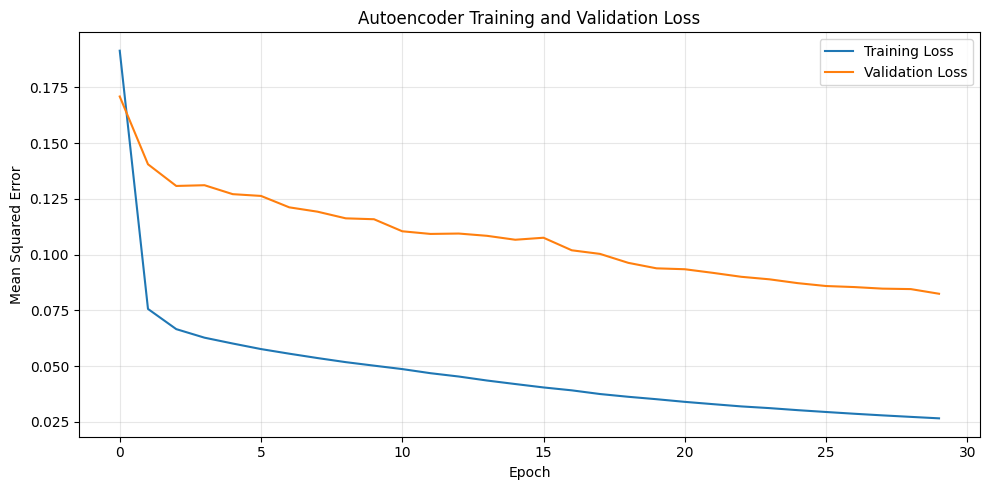

<Figure size 640x480 with 0 Axes>

In [ ]:
#3.2 Visualize training and validation loss
plt.figure(figsize=(10, 5))

plt.plot(
    history.history['loss'],
    label='Training Loss'
)

plt.plot(
    history.history['val_loss'],
    label='Validation Loss'
)

plt.title('Autoencoder Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Mean Squared Error')
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

plt.savefig(
    '/content/drive/MyDrive/CAPSTONE_PROJECT/04_autoecoder/Autoencoder_Training_And_Valisation_Loss.png',
    dpi=300,
    bbox_inches='tight'
)

##### OBESERVATIONS:
##### The autoencoder completed all 30 training epochs. The training loss decreased from 0.0260 to 0.0189.
##### The validation loss also decreased, with the lowest value of 0.0675 recorded at epoch 29.
##### The validation loss remained higher than the training loss.
##### This may be due to differences in sensor behaviour between the training and validation periods.
##### Further evaluation is needed to check anomaly detection performance.

In [ ]:
#3.3 Continue training for up to 20 more epochs

# Continue training the existing autoencoder
additional_history = autoencoder.fit(
    X_train_windows,
    X_train_windows,
    validation_data=(X_val_windows, X_val_windows),
    epochs=20,
    batch_size=256,
    shuffle=True,
    callbacks=[early_stopping],
    verbose=1
)

print("\nAdditional training completed.")
print("Additional epochs:", len(additional_history.history['loss']))
print("Best additional validation loss:",
      min(additional_history.history['val_loss']))

Epoch 1/20
164/164 ━━━━━━━━━━━━━━━━━━━━ 4s 27ms/step - loss: 0.0260 - val_loss: 0.0803
Epoch 2/20
164/164 ━━━━━━━━━━━━━━━━━━━━ 4s 24ms/step - loss: 0.0255 - val_loss: 0.0792
Epoch 3/20
164/164 ━━━━━━━━━━━━━━━━━━━━ 4s 23ms/step - loss: 0.0248 - val_loss: 0.0791
Epoch 4/20
164/164 ━━━━━━━━━━━━━━━━━━━━ 8s 38ms/step - loss: 0.0244 - val_loss: 0.0778
Epoch 5/20
164/164 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - loss: 0.0239 - val_loss: 0.0776
Epoch 6/20
164/164 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - loss: 0.0235 - val_loss: 0.0778
Epoch 7/20
164/164 ━━━━━━━━━━━━━━━━━━━━ 7s 30ms/step - loss: 0.0231 - val_loss: 0.0769
Epoch 8/20
164/164 ━━━━━━━━━━━━━━━━━━━━ 4s 21ms/step - loss: 0.0227 - val_loss: 0.0771
Epoch 9/20
164/164 ━━━━━━━━━━━━━━━━━━━━ 3s 18ms/step - loss: 0.0224 - val_loss: 0.0766
Epoch 10/20
164/164 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - loss: 0.0220 - val_loss: 0.0763
Epoch 11/20
164/164 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - loss: 0.0218 - val_loss: 0.0748
Epoch 12/20
164/164 ━━━━━━━━━━━━━━━━━━━━ 

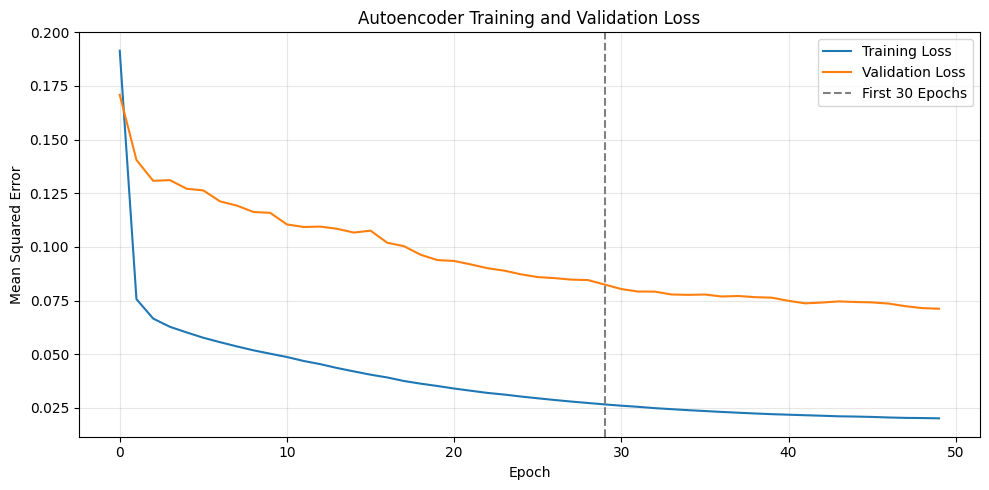

Total epochs: 50
Best validation loss: 0.07117723673582077


In [ ]:
#3.4 Plot the complete training history

# Combine the original and additional training results
all_train_loss = (
    history.history['loss'] +
    additional_history.history['loss']
)

all_val_loss = (
    history.history['val_loss'] +
    additional_history.history['val_loss']
)

plt.figure(figsize=(10, 5))

plt.plot(all_train_loss, label='Training Loss')
plt.plot(all_val_loss, label='Validation Loss')

plt.axvline(
    x=29,
    color='gray',
    linestyle='--',
    label='First 30 Epochs'
)

plt.title('Autoencoder Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Mean Squared Error')
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

print("Total epochs:", len(all_train_loss))
print("Best validation loss:", min(all_val_loss))

##### OBSERVATIONS:
##### I first trained the autoencoder for 30 epochs.
##### Since the validation loss was still decreasing, I continued training for another 20 epochs.
##### The validation loss improved from 0.0825 to 0.0712. The training loss also decreased to around 0.0201.
##### The validation loss is still higher than the training loss. I will now evaluate the model using reconstruction errors.

###Step 4: Save trained model

In [ ]:
from pathlib import Path
import json

# Create a folder for autoencoder results
autoencoder_dir = data_dir.parent / 'autoencoder_results'
autoencoder_dir.mkdir(parents=True, exist_ok=True)

# Save the trained model
autoencoder.save(autoencoder_dir / 'autoencoder_model.keras')

# Save training history
training_history = {
    'loss': [float(x) for x in all_train_loss],
    'val_loss': [float(x) for x in all_val_loss]
}

with open(autoencoder_dir / 'training_history.json', 'w') as f:
    json.dump(training_history, f, indent=4)

print("Model saved:", autoencoder_dir / 'autoencoder_model.keras')
print("Training history saved successfully.")

NameError: name 'autoencoder' is not defined

###Step 5: Verify saved model

In [ ]:
# Load the saved model
loaded_autoencoder = tf.keras.models.load_model(
    autoencoder_dir / 'autoencoder_model.keras'
)

# Check its output shape
sample = np.asarray(X_val_windows[:1])

prediction = loaded_autoencoder.predict(
    sample,
    verbose=0
)

print("Input shape:", sample.shape)
print("Output shape:", prediction.shape)
print("Model loaded successfully.")

Input shape: (1, 60, 15)
Output shape: (1, 60, 15)
Model loaded successfully.


##### OBSERVATIONS:
##### I saved the trained autoencoder and its training history
##### to Google Drive so I can reuse them without retraining.
##### I also loaded the saved model and checked its output shape.

###Step 6 : Calculate Reconstruction Errors

In [ ]:
#4.1 Calculate Reconstruction Erorrs
def calculate_reconstruction_errors(model, windows, batch_size=256):

    errors = []

    for start in range(0, len(windows), batch_size):

        batch = np.asarray(
            windows[start:start + batch_size]
        )

        reconstructed = model.predict(
            batch,
            verbose=0
        )

        batch_errors = np.mean(
            (batch - reconstructed) ** 2,
            axis=(1, 2)
        )

        errors.append(batch_errors)

    return np.concatenate(errors)


# Calculate reconstruction errors
train_errors = calculate_reconstruction_errors(
    autoencoder, X_train_windows
)

val_errors = calculate_reconstruction_errors(
    autoencoder, X_val_windows
)

eval_errors = calculate_reconstruction_errors(
    autoencoder, X_eval_windows
)

print("Training errors:", train_errors.shape)
print("Validation errors:", val_errors.shape)
print("Evaluation errors:", eval_errors.shape)

Training errors: (41938,)
Validation errors: (13749,)
Evaluation errors: (94307,)


In [ ]:
autoencoder = tf.keras.models.load_model(
    autoencoder_dir / 'autoencoder_model.keras'
)

###Step 7 : Analyze Reconstruction Errors

In [ ]:
autoencoder_dir = Path('/content/drive/MyDrive/CAPSTONE_PROJECT/autoencoder_results')
data_dir = Path('/content/drive/MyDrive/CAPSTONE_PROJECT/processed_data')

In [ ]:
autoencoder = tf.keras.models.load_model(
    autoencoder_dir / 'autoencoder_model.keras'
)

In [ ]:
X_train_windows = np.load(
    data_dir / 'X_train_windows.npy',
    mmap_mode='r'
)

X_val_windows = np.load(
    data_dir / 'X_val_windows.npy',
    mmap_mode='r'
)

X_eval_windows = np.load(
    data_dir / 'X_eval_windows.npy',
    mmap_mode='r'
)

print("Training:", X_train_windows.shape)
print("Validation:", X_val_windows.shape)
print("Evaluation:", X_eval_windows.shape)

Training: (41938, 60, 15)
Validation: (13749, 60, 15)
Evaluation: (94307, 60, 15)


In [ ]:
#Calculate reconstruction error statistics
error_summary = pd.DataFrame({
    'Training': pd.Series(train_errors),
    'Validation': pd.Series(val_errors),
    'Evaluation': pd.Series(eval_errors)
})

print(error_summary.describe().round(4))

         Training  Validation  Evaluation
count  41938.0000  13749.0000  94307.0000
mean       0.0198      0.0712      0.1164
std        0.0436      0.2260      0.3504
min        0.0004      0.0004      0.0004
25%        0.0007      0.0011      0.0052
50%        0.0056      0.0107      0.0279
75%        0.0267      0.0425      0.0596
max        1.3935      5.7972      5.3711


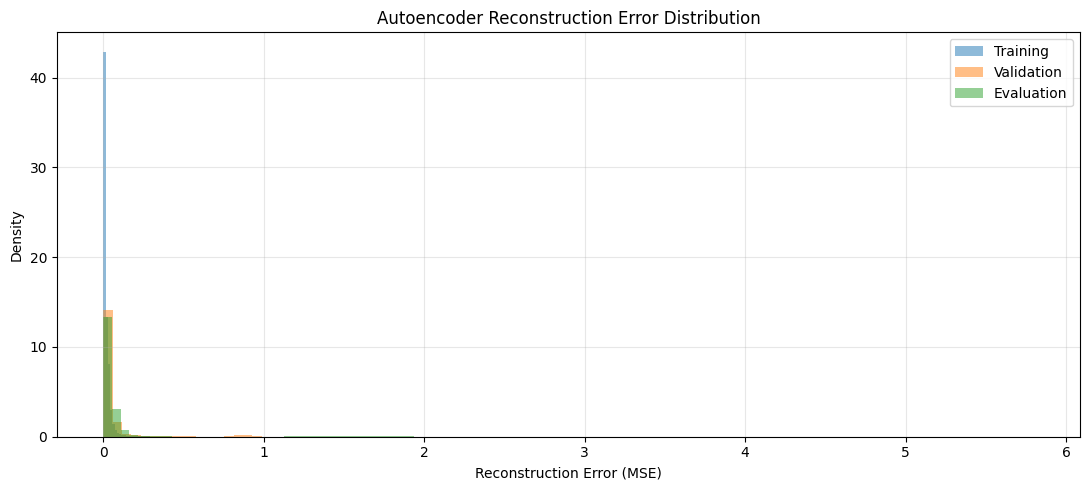

In [ ]:
#Plot reconstruction error distributions
plt.figure(figsize=(11, 5))

plt.hist(train_errors, bins=100, alpha=0.5,
         density=True, label='Training')

plt.hist(val_errors, bins=100, alpha=0.5,
         density=True, label='Validation')

plt.hist(eval_errors, bins=100, alpha=0.5,
         density=True, label='Evaluation')

plt.xlabel('Reconstruction Error (MSE)')
plt.ylabel('Density')
plt.title('Autoencoder Reconstruction Error Distribution')
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

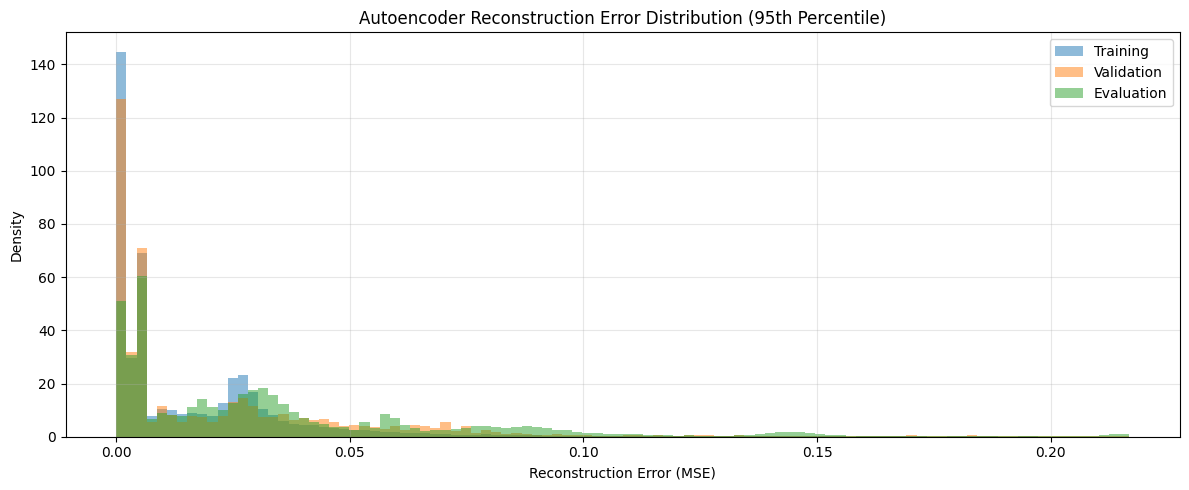

Visualization upper limit: 0.2168


<Figure size 640x480 with 0 Axes>

In [ ]:
#Improve the graph
# Calculate a common upper limit for visualization
all_errors = np.concatenate([
    train_errors,
    val_errors,
    eval_errors
])

plot_limit = np.percentile(all_errors, 95)

plt.figure(figsize=(12, 5))

plt.hist(
    train_errors,
    bins=100,
    range=(0, plot_limit),
    alpha=0.5,
    density=True,
    label='Training'
)

plt.hist(
    val_errors,
    bins=100,
    range=(0, plot_limit),
    alpha=0.5,
    density=True,
    label='Validation'
)

plt.hist(
    eval_errors,
    bins=100,
    range=(0, plot_limit),
    alpha=0.5,
    density=True,
    label='Evaluation'
)

plt.xlabel('Reconstruction Error (MSE)')
plt.ylabel('Density')
plt.title('Autoencoder Reconstruction Error Distribution (95th Percentile)')
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

plt.savefig(
    '/content/drive/MyDrive/CAPSTONE_PROJECT/04_autoecoder/Autoencoder_Error_Distribution.png',
    dpi=300,
    bbox_inches='tight'
)

print("Visualization upper limit:", round(plot_limit, 4))

##### OBSERVATIONS:
##### The training dataset has the lowest average reconstruction error, followed by the validation and evaluation datasets.
##### Most reconstruction errors are relatively small, but a few windows have much higher errors.
##### These high values made the original histogram difficult to read.
##### I adjusted the visualization to show the main distribution more clearly.
##### The evaluation errors are generally higher than the training errors,but further analysis is needed to check whether they relate to failures.

##Step 8 : Select Anomaly Threshold

In [ ]:
# Select threshold using validation reconstruction errors
ae_threshold = np.percentile(val_errors, 99)

print("Autoencoder anomaly threshold:", round(ae_threshold, 6))

Autoencoder anomaly threshold: 0.937345


In [ ]:
# Identify anomalies using the selected threshold
train_predictions = train_errors > ae_threshold
val_predictions = val_errors > ae_threshold
eval_predictions = eval_errors > ae_threshold

# Calculate anomaly counts and percentages
for name, predictions in [
    ('Training', train_predictions),
    ('Validation', val_predictions),
    ('Evaluation', eval_predictions)
]:
    count = np.sum(predictions)
    percentage = np.mean(predictions) * 100

    print(f"{name}: {count:,} anomalies ({percentage:.2f}%)")

Training: 12 anomalies (0.03%)
Validation: 138 anomalies (1.00%)
Evaluation: 4,376 anomalies (4.64%)


In [ ]:
# Save threshold and anomaly predictions
np.save(autoencoder_dir / 'ae_threshold.npy', ae_threshold)

np.save(autoencoder_dir / 'train_predictions.npy', train_predictions)
np.save(autoencoder_dir / 'val_predictions.npy', val_predictions)
np.save(autoencoder_dir / 'eval_predictions.npy', eval_predictions)

print("Autoencoder threshold and predictions saved successfully.")

Autoencoder threshold and predictions saved successfully.


##### OBSERVATIONS:
##### I selected an anomaly threshold of 0.937345 using the 99th percentile of the validation reconstruction errors.
##### The model identified 12 anomalous training windows, 138 validation windows and 4,376 evaluation windows.
##### The evaluation dataset had the highest anomaly percentage at 4.64%.
##### I will now check how these anomalies relate to the documented failure periods.

##Step 9 : Evaluate anomalies during failure periods

In [ ]:
# Load evaluation metadata
eval_metadata = pd.read_csv(
    data_dir / 'eval_metadata.csv',
    index_col=0,
    parse_dates=['timestamp']
)

# Load the indices of the last observation in each window
eval_window_end_indices = np.load(
    data_dir / 'eval_window_end_indices.npy'
)

print("Evaluation metadata:", eval_metadata.shape)
print("Evaluation window indices:", eval_window_end_indices.shape)
print("Autoencoder predictions:", eval_predictions.shape)

print("\nMetadata columns:")
print(eval_metadata.columns.tolist())

Evaluation metadata: (954384, 3)
Evaluation window indices: (94307,)
Autoencoder predictions: (94307,)

Metadata columns:
['timestamp', 'segment_id', 'failure_period']


In [ ]:
print("Evaluation metadata rows:", len(eval_metadata))
print("Metadata index range:",
      eval_metadata.index.min(),
      eval_metadata.index.max())

print("\nWindow indices:")
print("Count:", len(eval_window_end_indices))
print("Minimum:", eval_window_end_indices.min())
print("Maximum:", eval_window_end_indices.max())

print("\nFirst 5 window indices:")
print(eval_window_end_indices[:5])

print("\nFirst 5 metadata indices:")
print(eval_metadata.index[:5].tolist())

print("\nLast 5 metadata indices:")
print(eval_metadata.index[-5:].tolist())

print("\nPredictions:", len(eval_predictions))

Evaluation metadata rows: 954384
Metadata index range: 562564 1516947

Window indices:
Count: 94307
Minimum: 562623
Maximum: 1516947

First 5 window indices:
[562623 562633 562643 562653 562714]

First 5 metadata indices:
[562564, 562565, 562566, 562567, 562568]

Last 5 metadata indices:
[1516943, 1516944, 1516945, 1516946, 1516947]

Predictions: 94307


In [ ]:
# Check that the number of indices matches the predictions
assert len(eval_window_end_indices) == len(eval_predictions)

# Check that all window indices exist in the metadata
assert np.isin(
    eval_window_end_indices,
    eval_metadata.index
).all()

# Get metadata using the original dataset index labels
eval_window_metadata = eval_metadata.loc[
    eval_window_end_indices
].copy()

# Add reconstruction errors and anomaly predictions
eval_window_metadata['reconstruction_error'] = eval_errors
eval_window_metadata['ae_anomaly'] = eval_predictions

print("Window-level evaluation data:", eval_window_metadata.shape)

print(
    eval_window_metadata[
        ['timestamp', 'reconstruction_error', 'ae_anomaly']
    ].head()
)

Window-level evaluation data: (94307, 5)
                 timestamp  reconstruction_error  ae_anomaly
562623 2020-04-18 00:11:52              0.079310       False
562633 2020-04-18 00:13:53              0.078905       False
562643 2020-04-18 00:15:54              0.079388       False
562653 2020-04-18 00:17:55              0.075551       False
562714 2020-04-18 00:33:44              1.157577        True


##### Observation:
##### The saved window indices refer to the original dataset indices.
##### I used .loc[] to match each window with its ending timestamp.
##### I also added the reconstruction errors and anomaly predictions to the evaluation metadata for further analysis.

In [ ]:
#Evaluate the four failure periods
# Define the documented failure periods
failure_periods = [
    ('Failure 1', '2020-04-18 00:00:00', '2020-04-18 23:59:00'),
    ('Failure 2', '2020-05-29 23:30:00', '2020-05-30 06:00:00'),
    ('Failure 3', '2020-06-05 10:00:00', '2020-06-07 14:30:00'),
    ('Failure 4', '2020-07-15 14:30:00', '2020-07-15 19:00:00')
]

failure_results = []

for name, start, end in failure_periods:

    # Select windows ending within the failure period
    failure_windows = eval_window_metadata[
        (eval_window_metadata['timestamp'] >= pd.Timestamp(start)) &
        (eval_window_metadata['timestamp'] <= pd.Timestamp(end))
    ]

    total_windows = len(failure_windows)
    anomaly_count = int(failure_windows['ae_anomaly'].sum())

    anomaly_percentage = (
        anomaly_count / total_windows * 100
        if total_windows > 0 else 0
    )

    failure_results.append({
        'Failure': name,
        'Total Windows': total_windows,
        'Anomalous Windows': anomaly_count,
        'Anomaly Percentage': round(anomaly_percentage, 2)
    })

failure_results_df = pd.DataFrame(failure_results)

print(failure_results_df.to_string(index=False))

  Failure  Total Windows  Anomalous Windows  Anomaly Percentage
Failure 1            855                851               99.53
Failure 2            236                236              100.00
Failure 3           1719               1719              100.00
Failure 4            156                  0                0.00


##### Observation:
##### The autoencoder identified almost all windows in the first three documented failure periods as anomalies.
##### Failure 1 had an anomaly rate of 99.53%, while Failures 2 and 3 had anomaly rates of 100%.
##### However, no anomalous windows were detected in Failure 4.
##### This shows that the model responds differently to the four failure periods.
##### Need to check the anomaly rate outside failure periods to better understand the model's performance.

In [ ]:
# Identify windows ending within documented failure periods
failure_mask = pd.Series(
    False,
    index=eval_window_metadata.index
)

for name, start, end in failure_periods:

    failure_mask |= (
        (eval_window_metadata['timestamp'] >= pd.Timestamp(start)) &
        (eval_window_metadata['timestamp'] <= pd.Timestamp(end))
    )

# Separate windows inside and outside failure periods
inside_failure = eval_window_metadata.loc[failure_mask]
outside_failure = eval_window_metadata.loc[~failure_mask]

# Calculate anomaly counts
inside_anomalies = int(inside_failure['ae_anomaly'].sum())
outside_anomalies = int(outside_failure['ae_anomaly'].sum())

# Calculate anomaly percentages
inside_rate = inside_anomalies / len(inside_failure) * 100
outside_rate = outside_anomalies / len(outside_failure) * 100

print("Inside failure periods:")
print("Total windows:", len(inside_failure))
print("Anomalous windows:", inside_anomalies)
print("Anomaly percentage:", round(inside_rate, 2), "%")

print("\nOutside failure periods:")
print("Total windows:", len(outside_failure))
print("Anomalous windows:", outside_anomalies)
print("Anomaly percentage:", round(outside_rate, 2), "%")

Inside failure periods:
Total windows: 2966
Anomalous windows: 2806
Anomaly percentage: 94.61 %

Outside failure periods:
Total windows: 91341
Anomalous windows: 1570
Anomaly percentage: 1.72 %


##### Observation:
##### The autoencoder identified 94.61% of the windows within the documented failure periods as anomalies.
##### Outside these periods, the anomaly rate was 1.72%.
##### This shows that the model detects more unusual behaviour during the documented failure periods. were also identified outside the failure periods.
##### Further analysis is needed to understand these results.

In [ ]:
# Check the first detected anomaly during each failure period
detection_results = []

for name, start, end in failure_periods:

    start_time = pd.Timestamp(start)
    end_time = pd.Timestamp(end)

    # Select windows ending within the failure period
    failure_windows = eval_window_metadata[
        (eval_window_metadata['timestamp'] >= start_time) &
        (eval_window_metadata['timestamp'] <= end_time)
    ].sort_values('timestamp')

    # Select anomalous windows
    detected_windows = failure_windows[
        failure_windows['ae_anomaly']
    ]

    if len(detected_windows) > 0:

        first_detection = detected_windows['timestamp'].iloc[0]

        detection_delay = (
            first_detection - start_time
        ).total_seconds() / 60

        status = 'Detected'

    else:

        first_detection = pd.NaT
        detection_delay = np.nan
        status = 'Not Detected'

    detection_results.append({
        'Failure': name,
        'Status': status,
        'First Detection': first_detection,
        'Detection Delay (minutes)': round(detection_delay, 2)
        if pd.notna(detection_delay) else np.nan
    })

detection_results_df = pd.DataFrame(detection_results)

print(detection_results_df.to_string(index=False))

  Failure       Status     First Detection  Detection Delay (minutes)
Failure 1     Detected 2020-04-18 00:33:44                      33.73
Failure 2     Detected 2020-05-29 23:30:37                       0.62
Failure 3     Detected 2020-06-05 10:01:23                       1.38
Failure 4 Not Detected                 NaT                        NaN


##### Observation:
##### The autoencoder detected anomalies during three of the four documented failure periods.
##### Failure 1 was first detected after 33.73 minutes.
##### Failures 2 and 3 were detected after 0.62 and 1.38 minutes.
##### No anomalies were detected during Failure 4.
##### These results show detection after the failure started, so I will also check for possible warnings before each failure.

In [ ]:
# Check anomalies during the 24 hours before each failure
pre_failure_results = []

for name, start, end in failure_periods:

    start_time = pd.Timestamp(start)
    pre_start = start_time - pd.Timedelta(hours=24)

    # Select windows ending before the failure starts
    pre_failure_windows = eval_window_metadata[
        (eval_window_metadata['timestamp'] >= pre_start) &
        (eval_window_metadata['timestamp'] < start_time)
    ].sort_values('timestamp')

    total_windows = len(pre_failure_windows)

    # Select anomalous windows
    anomalous_windows = pre_failure_windows[
        pre_failure_windows['ae_anomaly']
    ]

    anomaly_count = len(anomalous_windows)

    anomaly_percentage = (
        anomaly_count / total_windows * 100
        if total_windows > 0 else np.nan
    )

    if anomaly_count > 0:

        last_anomaly_time = anomalous_windows['timestamp'].iloc[-1]

        warning_time = (
            start_time - last_anomaly_time
        ).total_seconds() / 60

    else:

        last_anomaly_time = pd.NaT
        warning_time = np.nan

    pre_failure_results.append({
        'Failure': name,
        'Total Windows': total_windows,
        'Anomalous Windows': anomaly_count,
        'Anomaly Percentage': round(anomaly_percentage, 2),
        'Last Anomaly Before Failure': last_anomaly_time,
        'Minutes Before Failure': round(warning_time, 2)
        if pd.notna(warning_time) else np.nan
    })

pre_failure_results_df = pd.DataFrame(pre_failure_results)

print(pre_failure_results_df.to_string(index=False))

  Failure  Total Windows  Anomalous Windows  Anomaly Percentage Last Anomaly Before Failure  Minutes Before Failure
Failure 1              0                  0                 NaN                         NaT                     NaN
Failure 2            731                  8                1.09         2020-05-29 23:28:58                    1.03
Failure 3            872                  5                0.57         2020-06-05 09:59:44                    0.27
Failure 4            613                 16                2.61         2020-07-15 13:32:51                   57.15


##### Observation:
##### I checked the 24-hour periods before the documented failures.
##### The model identified 8 anomalous windows before Failure 2, 5 before Failure 3 and 16 before Failure 4.
##### The last anomalies occurred 1.03, 0.27 and 57.15 minutes before the respective failure start times.
##### Although Failure 4 was not detected during its failure period, some anomalous windows were found before it started.
##### Further analysis is needed to check whether these anomalies could be useful as early warnings.

In [ ]:
# Select the 24 hours before Failure 4
failure_4_start = pd.Timestamp('2020-07-15 14:30:00')
pre_start = failure_4_start - pd.Timedelta(hours=24)

failure_4_pre = eval_window_metadata[
    (eval_window_metadata['timestamp'] >= pre_start) &
    (eval_window_metadata['timestamp'] < failure_4_start)
].copy()

# Get anomalous windows
failure_4_alerts = failure_4_pre[
    failure_4_pre['ae_anomaly']
].sort_values('timestamp')

# Show anomaly timestamps and reconstruction errors
print(
    failure_4_alerts[
        ['timestamp', 'reconstruction_error']
    ].to_string(index=False)
)

print("\nTotal anomalous windows:", len(failure_4_alerts))

          timestamp  reconstruction_error
2020-07-15 01:40:43              1.427241
2020-07-15 05:35:21              1.128745
2020-07-15 07:54:09              1.168786
2020-07-15 08:37:06              3.111244
2020-07-15 08:38:46              2.579277
2020-07-15 09:01:54              1.060199
2020-07-15 09:03:33              1.003346
2020-07-15 09:10:09              1.045709
2020-07-15 09:51:28              1.180918
2020-07-15 09:54:46              1.556483
2020-07-15 09:56:26              1.563553
2020-07-15 12:41:39              1.285210
2020-07-15 13:27:54              0.963223
2020-07-15 13:29:33              1.151674
2020-07-15 13:31:12              1.350929
2020-07-15 13:32:51              1.197512

Total anomalous windows: 16


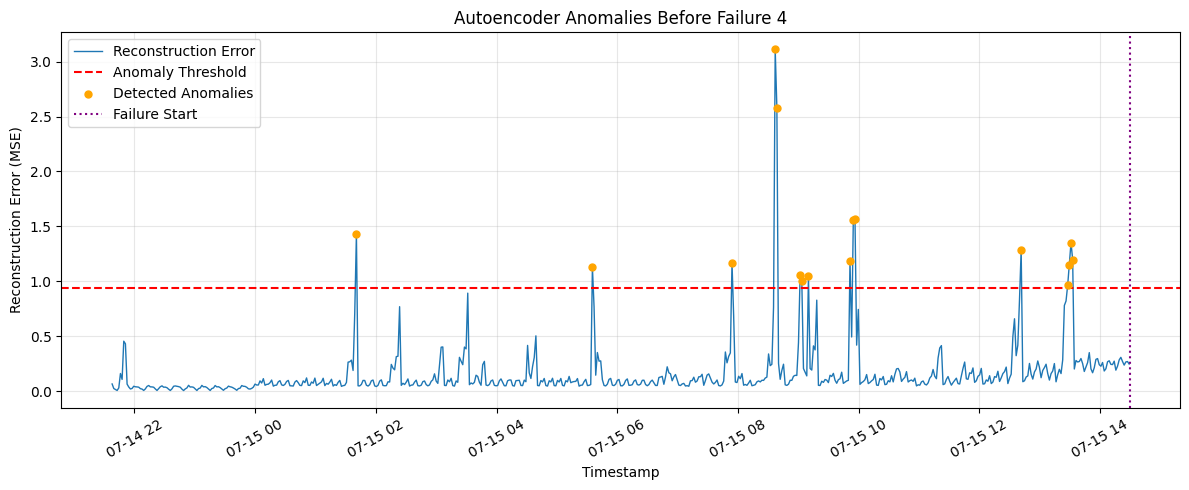

<Figure size 640x480 with 0 Axes>

In [ ]:
plt.figure(figsize=(12, 5))

plt.plot(
    failure_4_pre['timestamp'],
    failure_4_pre['reconstruction_error'],
    label='Reconstruction Error',
    linewidth=1
)

plt.axhline(
    ae_threshold,
    color='red',
    linestyle='--',
    label='Anomaly Threshold'
)

plt.scatter(
    failure_4_alerts['timestamp'],
    failure_4_alerts['reconstruction_error'],
    color='orange',
    s=25,
    label='Detected Anomalies',
    zorder=3
)

plt.axvline(
    failure_4_start,
    color='purple',
    linestyle=':',
    label='Failure Start'
)

plt.title('Autoencoder Anomalies Before Failure 4')
plt.xlabel('Timestamp')
plt.ylabel('Reconstruction Error (MSE)')
plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

plt.savefig(
    '/content/drive/MyDrive/CAPSTONE_PROJECT/04_autoecoder/Autoencoder Anomalies Before Failure 4.png',
    dpi=300,
    bbox_inches='tight'
)

##### Observation:
##### I examined the anomalies detected before Failure 4.
##### The model identified 16 anomalous windows during the previous 24 hours.
##### Some anomalies appeared individually, while others occurred close together.
##### The highest reconstruction error was 3.1112 at 08:37. Four consecutive windows were flagged between 13:27 and 13:32, around one hour before the failure.
##### These may indicate unusual sensor behaviour before the failure, but further analysis is needed.

## Step 10 : Compare the autoencoder with Isolation Forest

#####Step 10.1: Load Isolation Forest Evaluation Scores

In [ ]:
# Load Isolation Forest evaluation scores
baseline_dir = data_dir.parent / 'isolation_forest_results'

if_eval_scores = np.load(
    baseline_dir / 'eval_scores.npy'
)

print("Isolation Forest evaluation scores:", if_eval_scores.shape)
print("Autoencoder evaluation scores:", eval_errors.shape)
print("Evaluation metadata rows:", len(eval_metadata))

Isolation Forest evaluation scores: (954384,)
Autoencoder evaluation scores: (94307,)
Evaluation metadata rows: 954384


#####Step 10.2: Save and Verify Autoencoder Evaluation Results

In [ ]:
# Save failure evaluation results
failure_results_df.to_csv(
    autoencoder_dir / 'failure_results.csv',
    index=False
)

# Save detection timing results
detection_results_df.to_csv(
    autoencoder_dir / 'detection_timing.csv',
    index=False
)

# Save pre-failure analysis
pre_failure_results_df.to_csv(
    autoencoder_dir / 'pre_failure_results.csv',
    index=False
)

# Save window-level evaluation results
eval_window_metadata.to_csv(
    autoencoder_dir / 'eval_window_results.csv',
    index=True
)

# Save Failure 4 alerts
failure_4_alerts.to_csv(
    autoencoder_dir / 'failure_4_pre_failure_alerts.csv',
    index=True
)

print("All evaluation results saved successfully.")

All evaluation results saved successfully.


In [ ]:
required_files = [
    'autoencoder_model.keras',
    'training_history.json',
    'train_errors.npy',
    'val_errors.npy',
    'eval_errors.npy',
    'ae_threshold.npy',
    'train_predictions.npy',
    'val_predictions.npy',
    'eval_predictions.npy',
    'failure_results.csv',
    'detection_timing.csv',
    'pre_failure_results.csv',
    'eval_window_results.csv',
    'failure_4_pre_failure_alerts.csv'
]

for filename in required_files:
    path = autoencoder_dir / filename
    print(f"{filename}: {'Saved' if path.exists() else 'MISSING'}")

autoencoder_model.keras: Saved
training_history.json: Saved
train_errors.npy: MISSING
val_errors.npy: MISSING
eval_errors.npy: MISSING
ae_threshold.npy: Saved
train_predictions.npy: Saved
val_predictions.npy: Saved
eval_predictions.npy: Saved
failure_results.csv: Saved
detection_timing.csv: Saved
pre_failure_results.csv: Saved
eval_window_results.csv: Saved
failure_4_pre_failure_alerts.csv: Saved


#####Step 10.3: Recover and Verify Saved Reconstruction Errors

In [ ]:
eval_window_results = pd.read_csv(
    autoencoder_dir / 'eval_window_results.csv'
)

eval_errors = eval_window_results[
    'reconstruction_error'
].to_numpy()

np.save(autoencoder_dir / 'eval_errors.npy', eval_errors)

print("Evaluation errors recovered:", eval_errors.shape)

Evaluation errors recovered: (94307,)


In [ ]:
train_errors = calculate_reconstruction_errors(
    autoencoder, X_train_windows
)

val_errors = calculate_reconstruction_errors(
    autoencoder, X_val_windows
)

np.save(autoencoder_dir / 'train_errors.npy', train_errors)
np.save(autoencoder_dir / 'val_errors.npy', val_errors)

print("Training errors:", train_errors.shape)
print("Validation errors:", val_errors.shape)

Training errors: (41938,)
Validation errors: (13749,)


In [ ]:
for filename in [
    'train_errors.npy',
    'val_errors.npy',
    'eval_errors.npy'
]:
    path = autoencoder_dir / filename

    if path.exists():
        scores = np.load(path)
        print(f"{filename}: Saved {scores.shape}")
    else:
        print(f"{filename}: MISSING")

train_errors.npy: Saved (41938,)
val_errors.npy: Saved (13749,)
eval_errors.npy: Saved (94307,)


In [ ]:
val_threshold_check = np.percentile(val_errors, 99)

print("Recovered threshold:", round(val_threshold_check, 6))
print("Saved threshold:", round(float(np.load(
    autoencoder_dir / 'ae_threshold.npy'
)), 6))

Recovered threshold: 11.276641
Saved threshold: 0.937345


## Step 11 : Prepare Data for Window-Level Model Comparison

In [ ]:
autoencoder_dir = Path('/content/drive/MyDrive/CAPSTONE_PROJECT/autoencoder_results')
data_dir = Path('/content/drive/MyDrive/CAPSTONE_PROJECT/processed_data')

In [ ]:
import numpy as np
import pandas as pd
from pathlib import Path
from google.colab import drive

drive.mount('/content/drive')

data_dir = Path('/content/drive/MyDrive/CAPSTONE_PROJECT/processed_data')
baseline_dir = data_dir.parent / 'isolation_forest_results'
autoencoder_dir = data_dir.parent / 'autoencoder_results'

# Load Isolation Forest row-level scores
if_val_scores = np.load(baseline_dir / 'val_scores.npy')
if_eval_scores = np.load(baseline_dir / 'eval_scores.npy')

# Load autoencoder window-level scores
val_errors = np.load(autoencoder_dir / 'val_errors.npy')
eval_errors = np.load(autoencoder_dir / 'eval_errors.npy')

# Load metadata
val_metadata = pd.read_csv(
    data_dir / 'val_metadata.csv',
    index_col=0,
    parse_dates=['timestamp']
)

eval_metadata = pd.read_csv(
    data_dir / 'eval_metadata.csv',
    index_col=0,
    parse_dates=['timestamp']
)

# Load window ending indices
val_window_end_indices = np.load(
    data_dir / 'val_window_end_indices.npy'
)

eval_window_end_indices = np.load(
    data_dir / 'eval_window_end_indices.npy'
)

print("IF validation scores:", if_val_scores.shape)
print("IF evaluation scores:", if_eval_scores.shape)

print("\nAE validation scores:", val_errors.shape)
print("AE evaluation scores:", eval_errors.shape)

print("\nValidation window indices:", val_window_end_indices.shape)
print("Evaluation window indices:", eval_window_end_indices.shape)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
IF validation scores: (139419,)
IF evaluation scores: (954384,)

AE validation scores: (13749,)
AE evaluation scores: (94307,)

Validation window indices: (13749,)
Evaluation window indices: (94307,)


#####Step 11.1: Convert Isolation Forest Scores to Window-Level Scores

In [ ]:
#Calculate Isolation Forest window scores
def calculate_if_window_scores(
    row_scores,
    metadata,
    window_end_indices,
    window_size=60
):

    # Convert original index labels into row positions
    end_positions = metadata.index.get_indexer(
        window_end_indices
    )

    assert len(row_scores) == len(metadata)
    assert np.all(end_positions >= 0)

    start_positions = end_positions - window_size + 1

    assert np.all(start_positions >= 0)

    # Check that windows stay within the same recording segment
    assert 'segment_id' in metadata.columns

    segment_ids = metadata['segment_id'].to_numpy()

    assert np.all(
        segment_ids[start_positions] ==
        segment_ids[end_positions]
    )

    # Calculate the average IF score for each window
    cumulative_scores = np.concatenate([
        [0.0],
        np.cumsum(row_scores, dtype=np.float64)
    ])

    window_scores = (
        cumulative_scores[end_positions + 1] -
        cumulative_scores[start_positions]
    ) / window_size

    return window_scores


# Convert IF scores to window level
if_val_window_scores = calculate_if_window_scores(
    if_val_scores,
    val_metadata,
    val_window_end_indices
)

if_eval_window_scores = calculate_if_window_scores(
    if_eval_scores,
    eval_metadata,
    eval_window_end_indices
)

print("IF validation window scores:", if_val_window_scores.shape)
print("IF evaluation window scores:", if_eval_window_scores.shape)

print("\nAE validation window scores:", val_errors.shape)
print("AE evaluation window scores:", eval_errors.shape)

IF validation window scores: (13749,)
IF evaluation window scores: (94307,)

AE validation window scores: (13749,)
AE evaluation window scores: (94307,)


In [ ]:
#save converted scored
np.save(
    baseline_dir / 'if_val_window_scores.npy',
    if_val_window_scores
)

np.save(
    baseline_dir / 'if_eval_window_scores.npy',
    if_eval_window_scores
)

print("Isolation Forest window scores saved successfully.")

Isolation Forest window scores saved successfully.


#####Step 11.2: Select Thresholds and Generate Window-Level Predictions

In [ ]:
# Calculate the IF threshold using validation window scores
if_window_threshold = np.percentile(
    if_val_window_scores, 99
)

# Load the saved AE threshold
ae_threshold = float(
    np.load(autoencoder_dir / 'ae_threshold.npy')
)

# Calculate window-level anomaly predictions
if_val_window_predictions = (
    if_val_window_scores > if_window_threshold
)

if_eval_window_predictions = (
    if_eval_window_scores > if_window_threshold
)

ae_val_window_predictions = (
    val_errors > ae_threshold
)

ae_eval_window_predictions = (
    eval_errors > ae_threshold
)

# Display threshold values
print(f"IF window threshold: {if_window_threshold:.6f}")
print(f"AE window threshold: {ae_threshold:.6f}")

# Display anomaly counts
print("\nValidation anomaly counts:")
print("IF:", if_val_window_predictions.sum())
print("AE:", ae_val_window_predictions.sum())

print("\nEvaluation anomaly counts:")
print("IF:", if_eval_window_predictions.sum())
print("AE:", ae_eval_window_predictions.sum())

# Display anomaly percentages
print("\nEvaluation anomaly percentages:")
print(f"IF: {if_eval_window_predictions.mean() * 100:.2f}%")
print(f"AE: {ae_eval_window_predictions.mean() * 100:.2f}%")

IF window threshold: 0.700428
AE window threshold: 0.937345

Validation anomaly counts:
IF: 138
AE: 5413

Evaluation anomaly counts:
IF: 3205
AE: 4376

Evaluation anomaly percentages:
IF: 3.40%
AE: 4.64%


In [ ]:
# Save IF window-level threshold
np.save(
    baseline_dir / 'if_window_threshold.npy',
    if_window_threshold
)

# Save IF window-level predictions
np.save(
    baseline_dir / 'if_val_window_predictions.npy',
    if_val_window_predictions
)

np.save(
    baseline_dir / 'if_eval_window_predictions.npy',
    if_eval_window_predictions
)

print("IF window threshold and predictions saved successfully.")

IF window threshold and predictions saved successfully.


##### Observation:
##### I selected the Isolation Forest threshold using the 99th percentile of its validation window scores.
##### This is the same threshold selection method used for the autoencoder.
##### Both models use their own validation scores to determine the threshold.
##### The evaluation results will show how their anomaly detection rates differ on the same windows.

#####Step 11.3: Verify and Correct Autoencoder Validation Errors

In [ ]:
# Check whether the saved AE threshold matches validation errors
current_ae_threshold = np.percentile(val_errors, 99)

print(f"Saved AE threshold: {ae_threshold:.6f}")
print(f"99th percentile of loaded AE validation errors: {current_ae_threshold:.6f}")

print("\nValidation error statistics:")
print(pd.Series(val_errors).describe())

print("\nSaved AE evaluation anomaly count:")
saved_ae_predictions = np.load(
    autoencoder_dir / 'eval_predictions.npy'
)

print(saved_ae_predictions.sum())

print("\nCurrent AE evaluation anomaly count:")
print(ae_eval_window_predictions.sum())

Saved AE threshold: 0.937345
99th percentile of loaded AE validation errors: 11.276641

Validation error statistics:
count    13749.000000
mean         1.329561
std          1.941757
min          0.465539
25%          0.547518
50%          0.744400
75%          1.102540
max         17.620874
dtype: float64

Saved AE evaluation anomaly count:
4376

Current AE evaluation anomaly count:
4376


In [ ]:
# Load the saved autoencoder results
saved_val_errors = np.load(
    autoencoder_dir / 'val_errors.npy'
)

saved_eval_errors = np.load(
    autoencoder_dir / 'eval_errors.npy'
)

saved_val_predictions = np.load(
    autoencoder_dir / 'val_predictions.npy'
)

saved_eval_predictions = np.load(
    autoencoder_dir / 'eval_predictions.npy'
)

saved_threshold = float(
    np.load(autoencoder_dir / 'ae_threshold.npy')
)

# Check the saved validation results
print("Validation:")
print("Error shape:", saved_val_errors.shape)
print("Mean error:", saved_val_errors.mean())
print("99th percentile:", np.percentile(saved_val_errors, 99))
print("Saved anomaly count:", saved_val_predictions.sum())
print("Recalculated anomaly count:",
      (saved_val_errors > saved_threshold).sum())

# Check the saved evaluation results
print("\nEvaluation:")
print("Error shape:", saved_eval_errors.shape)
print("Mean error:", saved_eval_errors.mean())
print("Saved anomaly count:", saved_eval_predictions.sum())
print("Recalculated anomaly count:",
      (saved_eval_errors > saved_threshold).sum())

# Compare evaluation errors with the saved CSV
saved_eval_results = pd.read_csv(
    autoencoder_dir / 'eval_window_results.csv'
)

csv_eval_errors = saved_eval_results[
    'reconstruction_error'
].to_numpy()

print("\nEvaluation CSV comparison:")
print("CSV mean error:", csv_eval_errors.mean())
print("Saved NPY matches CSV:",
      np.allclose(saved_eval_errors, csv_eval_errors))

# Check whether the saved predictions match the CSV
print("Saved predictions match CSV:",
      np.array_equal(
          saved_eval_predictions,
          saved_eval_results['ae_anomaly'].astype(bool).to_numpy()
      ))

Validation:
Error shape: (13749,)
Mean error: 1.3295612
99th percentile: 11.276641
Saved anomaly count: 138
Recalculated anomaly count: 5413

Evaluation:
Error shape: (94307,)
Mean error: 0.1163568915588526
Saved anomaly count: 4376
Recalculated anomaly count: 4376

Evaluation CSV comparison:
CSV mean error: 0.1163568915588526
Saved NPY matches CSV: True
Saved predictions match CSV: True


In [ ]:
import tensorflow as tf

# Load the saved trained autoencoder
autoencoder = tf.keras.models.load_model(
    autoencoder_dir / 'autoencoder_model.keras'
)

# Load the original validation windows
X_val_windows = np.load(
    data_dir / 'X_val_windows.npy',
    mmap_mode='r'
)

print("Validation windows:", X_val_windows.shape)
print("Model input shape:", autoencoder.input_shape)
print("Model output shape:", autoencoder.output_shape)

# Calculate reconstruction errors
def calculate_reconstruction_errors(model, windows, batch_size=256):

    errors = []

    for start in range(0, len(windows), batch_size):

        batch = np.asarray(
            windows[start:start + batch_size]
        )

        reconstructed = model.predict(
            batch,
            verbose=0
        )

        batch_errors = np.mean(
            (batch - reconstructed) ** 2,
            axis=(1, 2)
        )

        errors.append(batch_errors)

    return np.concatenate(errors)


# Recalculate validation reconstruction errors
recalculated_val_errors = calculate_reconstruction_errors(
    autoencoder,
    X_val_windows
)

print("\nRecalculated validation errors:")
print("Mean:", recalculated_val_errors.mean())
print("99th percentile:", np.percentile(recalculated_val_errors, 99))

print("\nSaved AE threshold:", saved_threshold)

print("Validation anomalies:",
      (recalculated_val_errors > saved_threshold).sum())

Validation windows: (13749, 60, 15)
Model input shape: (None, 60, 15)
Model output shape: (None, 60, 15)

Recalculated validation errors:
Mean: 0.07117723
99th percentile: 0.9373453

Saved AE threshold: 0.9373453259468079
Validation anomalies: 138


In [ ]:
# Save the corrected validation reconstruction errors
np.save(
    autoencoder_dir / 'val_errors.npy',
    recalculated_val_errors
)

# Update the current variable
val_errors = recalculated_val_errors

# Verify the saved file
verified_val_errors = np.load(
    autoencoder_dir / 'val_errors.npy'
)

print("Saved validation errors:", verified_val_errors.shape)
print("Mean error:", verified_val_errors.mean())
print("99th percentile:", np.percentile(verified_val_errors, 99))
print("Validation anomalies:",
      (verified_val_errors > saved_threshold).sum())

Saved validation errors: (13749,)
Mean error: 0.07117723
99th percentile: 0.9373453
Validation anomalies: 138


##### Observation:
##### I found that the saved validation reconstruction errors did not match the original autoencoder threshold.
##### I recalculated the errors using the saved trained model and the original validation windows.
##### The recalculated results matched the original threshold and anomaly count, so I replaced the incorrect file.

## Step 12 : Prepare the Model Comparison DataFrame

In [ ]:
#Prepare the comparison DataFrame
# Get the metadata for the evaluation windows
comparison_df = eval_metadata.loc[
    eval_window_end_indices
].copy()

# Add Isolation Forest results
comparison_df['if_score'] = if_eval_window_scores
comparison_df['if_anomaly'] = if_eval_window_predictions

# Add Autoencoder results
comparison_df['ae_score'] = eval_errors
comparison_df['ae_anomaly'] = ae_eval_window_predictions

# Check the results
print("Comparison shape:", comparison_df.shape)

print("\nIsolation Forest anomalies:",
      comparison_df['if_anomaly'].sum())

print("Autoencoder anomalies:",
      comparison_df['ae_anomaly'].sum())

print("\nFirst five rows:")
display(comparison_df.head())


Comparison shape: (94307, 7)

Isolation Forest anomalies: 3205
Autoencoder anomalies: 4376

First five rows:


,timestamp,segment_id,failure_period,if_score,if_anomaly,ae_score,ae_anomaly
562623,2020-04-18 00:11:52,112,1,0.508988,False,0.079310,False
562633,2020-04-18 00:13:53,112,1,0.508988,False,0.078905,False
562643,2020-04-18 00:15:54,112,1,0.508988,False,0.079388,False
562653,2020-04-18 00:17:55,112,1,0.505529,False,0.075551,False
562714,2020-04-18 00:33:44,113,1,0.692634,False,1.157577,True


##### Observation:
##### I combined the Isolation Forest and autoencoder results using the same evaluation windows.
##### Each row now contains the anomaly scores and predictions from both models for the same window.
##### This will be used to compare their results during the documented failure periods.

In [ ]:
# Save the comparison results
comparison_df.to_csv(
    autoencoder_dir / 'model_comparison_windows.csv',
    index=True
)

# Save Isolation Forest window-level results
np.save(
    baseline_dir / 'if_val_window_scores.npy',
    if_val_window_scores
)

np.save(
    baseline_dir / 'if_eval_window_scores.npy',
    if_eval_window_scores
)

np.save(
    baseline_dir / 'if_window_threshold.npy',
    if_window_threshold
)

np.save(
    baseline_dir / 'if_val_window_predictions.npy',
    if_val_window_predictions
)

np.save(
    baseline_dir / 'if_eval_window_predictions.npy',
    if_eval_window_predictions
)

# Verify the comparison results
print("Comparison rows:", len(comparison_df))
print("IF anomalies:", comparison_df['if_anomaly'].sum())
print("AE anomalies:", comparison_df['ae_anomaly'].sum())

print("\nComparison file saved:",
      (autoencoder_dir / 'model_comparison_windows.csv').exists())

Comparison rows: 94307
IF anomalies: 3205
AE anomalies: 4376

Comparison file saved: True


#####Step 12.1: Verify Saved Results and Window Alignment

In [ ]:
import numpy as np
import pandas as pd
from pathlib import Path
from google.colab import drive

drive.mount('/content/drive')

data_dir = Path('/content/drive/MyDrive/CAPSTONE_PROJECT/processed_data')
baseline_dir = data_dir.parent / 'isolation_forest_results'
autoencoder_dir = data_dir.parent / 'autoencoder_results'

# Load Isolation Forest row-level scores
if_val_scores = np.load(baseline_dir / 'val_scores.npy')
if_eval_scores = np.load(baseline_dir / 'eval_scores.npy')

# Load autoencoder window-level scores
val_errors = np.load(autoencoder_dir / 'val_errors.npy')
eval_errors = np.load(autoencoder_dir / 'eval_errors.npy')

# Load metadata
val_metadata = pd.read_csv(
    data_dir / 'val_metadata.csv',
    index_col=0,
    parse_dates=['timestamp']
)

eval_metadata = pd.read_csv(
    data_dir / 'eval_metadata.csv',
    index_col=0,
    parse_dates=['timestamp']
)

# Load window ending indices
val_window_end_indices = np.load(
    data_dir / 'val_window_end_indices.npy'
)

eval_window_end_indices = np.load(
    data_dir / 'eval_window_end_indices.npy'
)

autoencoder_dir = Path('/content/drive/MyDrive/CAPSTONE_PROJECT/autoencoder_results')
data_dir = Path('/content/drive/MyDrive/CAPSTONE_PROJECT/processed_data')


print("IF validation scores:", if_val_scores.shape)
print("IF evaluation scores:", if_eval_scores.shape)

print("\nAE validation scores:", val_errors.shape)
print("AE evaluation scores:", eval_errors.shape)

print("\nValidation window indices:", val_window_end_indices.shape)
print("Evaluation window indices:", eval_window_end_indices.shape)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
IF validation scores: (139419,)
IF evaluation scores: (954384,)

AE validation scores: (13749,)
AE evaluation scores: (94307,)

Validation window indices: (13749,)
Evaluation window indices: (94307,)


In [ ]:
#Load data

data_dir = Path('/content/drive/MyDrive/CAPSTONE_PROJECT/processed_data')

# Load temporal windows
X_train_windows = np.load(
    data_dir / 'X_train_windows.npy',
    mmap_mode='r'
)

X_val_windows = np.load(
    data_dir / 'X_val_windows.npy',
    mmap_mode='r'
)

X_eval_windows = np.load(
    data_dir / 'X_eval_windows.npy',
    mmap_mode='r'
)

print("Training window:", X_train_windows.shape)
print("Validation window:", X_val_windows.shape)
print("Evaluation window:", X_eval_windows.shape)

print("\nData type:", X_train_windows.dtype)

Training window: (41938, 60, 15)
Validation window: (13749, 60, 15)
Evaluation window: (94307, 60, 15)

Data type: float32


In [ ]:
# Check the saved results before continuing

ae_threshold = float(
    np.load(autoencoder_dir / 'ae_threshold.npy')
)

val_errors = np.load(
    autoencoder_dir / 'val_errors.npy'
)

eval_errors = np.load(
    autoencoder_dir / 'eval_errors.npy'
)

if_eval_window_predictions = np.load(
    baseline_dir / 'if_eval_window_predictions.npy'
)

print("AE threshold:", round(ae_threshold, 6))

print("Validation threshold matches:",
      np.isclose(np.percentile(val_errors, 99), ae_threshold))

print("AE evaluation anomalies:",
      (eval_errors > ae_threshold).sum())

print("IF evaluation anomalies:",
      if_eval_window_predictions.sum())

AE threshold: 0.937345
Validation threshold matches: True
AE evaluation anomalies: 4376
IF evaluation anomalies: 3205


In [ ]:
# Verify IF window alignment with the original data

for name, metadata, end_indices, windows in [
    ('Validation', val_metadata, val_window_end_indices, X_val_windows),
    ('Evaluation', eval_metadata, eval_window_end_indices, X_eval_windows)
]:

    end_positions = metadata.index.get_indexer(end_indices)
    start_positions = end_positions - 59

    # Check original index continuity
    row_indices = metadata.index.to_numpy()

    index_continuity = np.all(
        row_indices[end_positions] -
        row_indices[start_positions] == 59
    )

    # Check recording segment boundaries
    segments = metadata['segment_id'].to_numpy()

    same_segments = np.all(
        segments[start_positions] ==
        segments[end_positions]
    )

    print(f"\n{name}:")
    print("Index continuity:", index_continuity)
    print("Same recording segment:", same_segments)
    print("Window count matches:", len(end_indices) == len(windows))


Validation:
Index continuity: True
Same recording segment: True
Window count matches: True

Evaluation:
Index continuity: True
Same recording segment: True
Window count matches: True


### STEP 13 : Compare both models during the codumented failure periods

In [ ]:
# Load the saved model comparison results
comparison_df = pd.read_csv(
    autoencoder_dir / 'model_comparison_windows.csv',
    index_col=0,
    parse_dates=['timestamp']
)

print("Comparison data:", comparison_df.shape)

print("IF anomalies:", comparison_df['if_anomaly'].sum())
print("AE anomalies:", comparison_df['ae_anomaly'].sum())

Comparison data: (94307, 7)
IF anomalies: 3205
AE anomalies: 4376


In [ ]:
# Define the documented failure periods
failure_periods = [
    ('Failure 1', '2020-04-18 00:00:00', '2020-04-18 23:59:00'),
    ('Failure 2', '2020-05-29 23:30:00', '2020-05-30 06:00:00'),
    ('Failure 3', '2020-06-05 10:00:00', '2020-06-07 14:30:00'),
    ('Failure 4', '2020-07-15 14:30:00', '2020-07-15 19:00:00')
]

comparison_results = []

# Track windows inside documented failure periods
failure_mask = pd.Series(
    False,
    index=comparison_df.index
)

for name, start, end in failure_periods:

    period_mask = (
        (comparison_df['timestamp'] >= pd.Timestamp(start)) &
        (comparison_df['timestamp'] <= pd.Timestamp(end))
    )

    failure_mask |= period_mask

    period_data = comparison_df.loc[period_mask]

    total_windows = len(period_data)

    if_count = int(period_data['if_anomaly'].sum())
    ae_count = int(period_data['ae_anomaly'].sum())

    comparison_results.append({
        'Period': name,
        'Windows': total_windows,
        'IF Anomalous Windows': if_count,
        'IF Anomaly Rate (%)': round(
            if_count / total_windows * 100, 2
        ) if total_windows else 0,
        'AE Anomalous Windows': ae_count,
        'AE Anomaly Rate (%)': round(
            ae_count / total_windows * 100, 2
        ) if total_windows else 0
    })

# Compare windows outside documented failures
outside_data = comparison_df.loc[~failure_mask]

total_outside = len(outside_data)
if_outside = int(outside_data['if_anomaly'].sum())
ae_outside = int(outside_data['ae_anomaly'].sum())

comparison_results.append({
    'Period': 'Outside documented failures',
    'Windows': total_outside,
    'IF Anomalous Windows': if_outside,
    'IF Anomaly Rate (%)': round(
        if_outside / total_outside * 100, 2
    ),
    'AE Anomalous Windows': ae_outside,
    'AE Anomaly Rate (%)': round(
        ae_outside / total_outside * 100, 2
    )
})

comparison_results_df = pd.DataFrame(comparison_results)

display(comparison_results_df)

,Period,Windows,IF Anomalous Windows,IF Anomaly Rate (%),AE Anomalous Windows,AE Anomaly Rate (%)
0,Failure 1,855,6,0.70,851,99.53
1,Failure 2,236,219,92.80,236,100.00
2,Failure 3,1719,1716,99.83,1719,100.00
3,Failure 4,156,31,19.87,0,0.00
4,Outside documented failures,91341,1233,1.35,1570,1.72


In [ ]:
# Save the failure-period comparison
comparison_results_df.to_csv(
    autoencoder_dir / 'if_ae_failure_comparison.csv',
    index=False
)

print("Model comparison results saved successfully.")

Model comparison results saved successfully.


##### Observation:
##### I compared Isolation Forest and the autoencoder using the same evaluation windows.
##### The autoencoder had higher anomaly rates during the first three documented failure periods.
##### However, it did not flag any windows during Failure 4, while Isolation Forest flagged 19.87% of those windows.
##### Isolation Forest also had a slightly lower anomaly rate outside the documented failure periods.
##### This shows that the two models respond differently to the documented failure periods.

### STEP 14 : Investigate Failure 4 Detection Differences

##### Step 14.1: Examine Anomaly Scores During Failure 4

In [ ]:
# Select evaluation windows during Failure 4

failure4_data = comparison_df[
    (comparison_df['timestamp'] >= '2020-07-15 14:30:00') &
    (comparison_df['timestamp'] <= '2020-07-15 19:00:00')
].copy()

print("Failure 4 windows:", len(failure4_data))
print("\nAvailable columns:")
print(failure4_data.columns.tolist())

print("\nAnomaly predictions:")
print("Isolation Forest:", failure4_data['if_anomaly'].sum())
print("Autoencoder:", failure4_data['ae_anomaly'].sum())

display(failure4_data.head())

Failure 4 windows: 156

Available columns:
['timestamp', 'segment_id', 'failure_period', 'if_score', 'if_anomaly', 'ae_score', 'ae_anomaly']

Anomaly predictions:
Isolation Forest: 31
Autoencoder: 0


,timestamp,segment_id,failure_period,if_score,if_anomaly,ae_score,ae_anomaly
1171097,2020-07-15 14:30:40,252,1,0.616314,False,0.300817,False
1171107,2020-07-15 14:32:19,252,1,0.615509,False,0.171711,False
1171117,2020-07-15 14:33:58,252,1,0.636420,False,0.271075,False
1171127,2020-07-15 14:35:37,252,1,0.642840,False,0.317792,False
1171137,2020-07-15 14:37:16,252,1,0.645544,False,0.378470,False


##### Step 14.2: Compare Failure 4 Anomaly Scores with Model Thresholds

In [ ]:
# Compare anomaly scores and thresholds during Failure 4

if_threshold = float(
    np.load(baseline_dir / 'if_window_threshold.npy')
)

ae_threshold = float(
    np.load(autoencoder_dir / 'ae_threshold.npy')
)

print("Isolation Forest threshold:", round(if_threshold, 6))
print("Autoencoder threshold:", round(ae_threshold, 6))

# Summarize scores during Failure 4
score_summary = pd.DataFrame({
    'Model': ['Isolation Forest', 'Autoencoder'],
    'Minimum Score': [
        failure4_data['if_score'].min(),
        failure4_data['ae_score'].min()
    ],
    'Mean Score': [
        failure4_data['if_score'].mean(),
        failure4_data['ae_score'].mean()
    ],
    'Maximum Score': [
        failure4_data['if_score'].max(),
        failure4_data['ae_score'].max()
    ],
    'Threshold': [
        if_threshold,
        ae_threshold
    ],
    'Windows Above Threshold': [
        (failure4_data['if_score'] > if_threshold).sum(),
        (failure4_data['ae_score'] > ae_threshold).sum()
    ]
})

display(score_summary.round(6))

# Verify saved predictions match threshold comparisons
assert (
    (failure4_data['if_score'] > if_threshold).to_numpy()
    == failure4_data['if_anomaly'].to_numpy()
).all()

assert (
    (failure4_data['ae_score'] > ae_threshold).to_numpy()
    == failure4_data['ae_anomaly'].to_numpy()
).all()

print("\nThreshold and prediction checks passed.")

Isolation Forest threshold: 0.700428
Autoencoder threshold: 0.937345


,Model,Minimum Score,Mean Score,Maximum Score,Threshold,Windows Above Threshold
0,Isolation Forest,0.589038,0.670424,0.708730,0.700428,31
1,Autoencoder,0.072842,0.291224,0.561805,0.937345,0



Threshold and prediction checks passed.


##### Observation:
##### During Failure 4, Isolation Forest detected 31 out of 156 windows, while the autoencoder detected none.
##### The maximum IF score (0.708730) was slightly above its threshold (0.700428).
##### The maximum AE reconstruction error (0.561805) remained below its threshold (0.937345).
##### The threshold checks confirmed that both models' predictions were calculated correctly.
##### This suggests that the models respond differently to the sensor patterns during Failure 4.

##### Step 14.3: Visualize Model Anomaly Scores During Failure 4

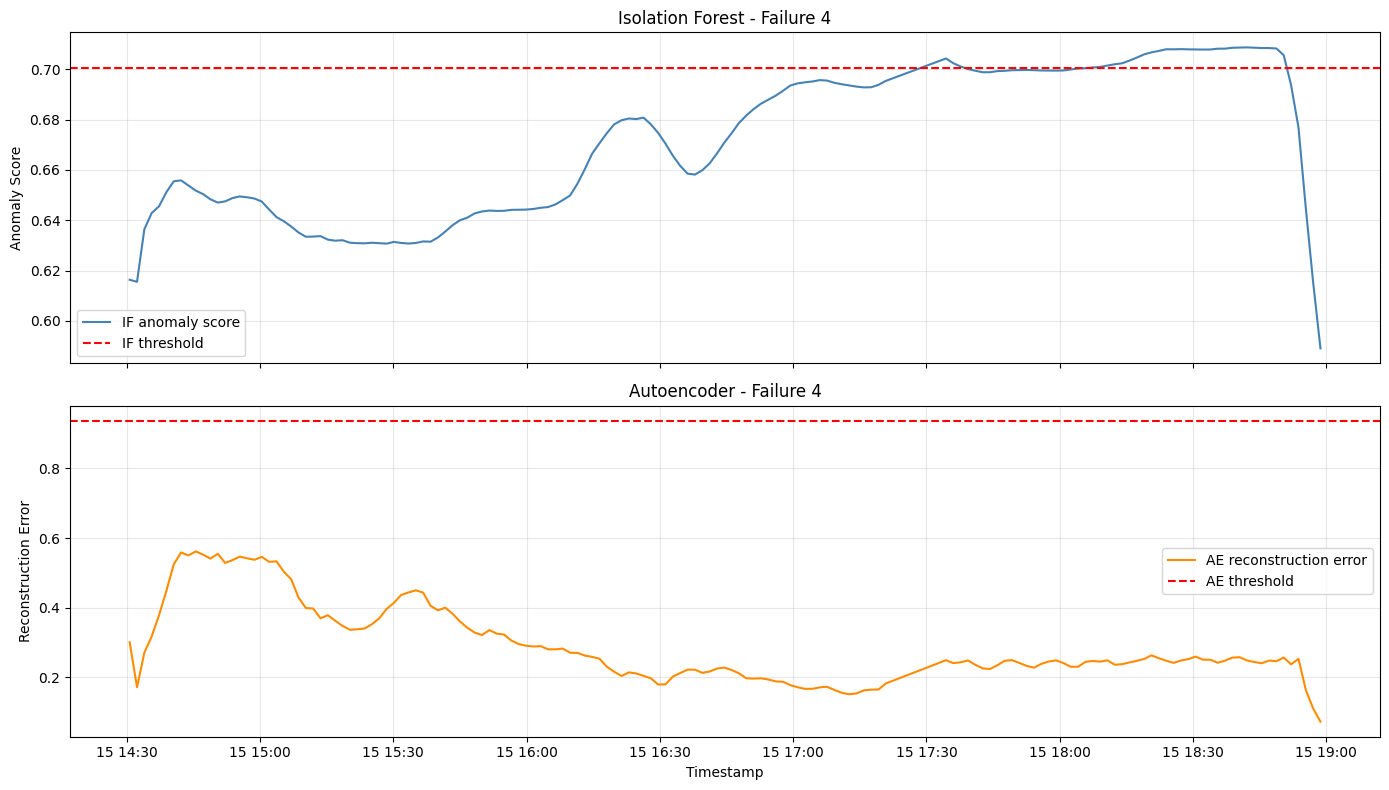

In [ ]:
# Visualize anomaly scores during Failure 4

import matplotlib.pyplot as plt

failure4_sorted = failure4_data.sort_values('timestamp')

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

# Isolation Forest scores
axes[0].plot(
    failure4_sorted['timestamp'],
    failure4_sorted['if_score'],
    color='steelblue',
    label='IF anomaly score'
)

axes[0].axhline(
    if_threshold,
    color='red',
    linestyle='--',
    label='IF threshold'
)

axes[0].set_title('Isolation Forest - Failure 4')
axes[0].set_ylabel('Anomaly Score')
axes[0].legend()
axes[0].grid(alpha=0.3)

# Autoencoder reconstruction errors
axes[1].plot(
    failure4_sorted['timestamp'],
    failure4_sorted['ae_score'],
    color='darkorange',
    label='AE reconstruction error'
)

axes[1].axhline(
    ae_threshold,
    color='red',
    linestyle='--',
    label='AE threshold'
)

axes[1].set_title('Autoencoder - Failure 4')
axes[1].set_ylabel('Reconstruction Error')
axes[1].set_xlabel('Timestamp')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()

# Save the figure
plt.savefig(
    autoencoder_dir / 'failure4_model_score_comparison.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

##### Observation:
##### During Failure 4, Isolation Forest anomaly scores generally increased and exceeded the threshold
##### mainly towards the later part of the failure period. In contrast, autoencoder reconstruction errors were
##### higher at the beginning and gradually decreased. All AE scores remained below the selected threshold.
##### This indicates that the two models respond differently to the sensor behaviour during Failure 4.
##### Further investigation is needed to understand which sensor patterns contribute to this difference.

In [1]:
# Resume Step 15 without retraining

import numpy as np
import pandas as pd
import tensorflow as tf
from pathlib import Path
from google.colab import drive

drive.mount('/content/drive')

# Project folders
data_dir = Path('/content/drive/MyDrive/CAPSTONE_PROJECT/processed_data')
autoencoder_dir = data_dir.parent / 'autoencoder_results'
baseline_dir = data_dir.parent / 'isolation_forest_results'

# Load trained autoencoder
autoencoder = tf.keras.models.load_model(
    autoencoder_dir / 'autoencoder_model.keras'
)

# Load evaluation windows
X_eval_windows = np.load(
    data_dir / 'X_eval_windows.npy',
    mmap_mode='r'
)

# Load evaluation metadata and window indices
eval_metadata = pd.read_csv(
    data_dir / 'eval_metadata.csv',
    index_col=0,
    parse_dates=['timestamp']
)

eval_window_end_indices = np.load(
    data_dir / 'eval_window_end_indices.npy'
)

# Load saved model comparison
comparison_df = pd.read_csv(
    autoencoder_dir / 'model_comparison_windows.csv',
    index_col=0,
    parse_dates=['timestamp']
)

# Select Failure 4 windows
failure4_data = comparison_df[
    (comparison_df['timestamp'] >= '2020-07-15 14:30:00') &
    (comparison_df['timestamp'] <= '2020-07-15 19:00:00')
].copy()

# Verify restored data
assert len(X_eval_windows) == len(eval_window_end_indices)
assert len(comparison_df) == len(X_eval_windows)
assert len(failure4_data) == 156

print("Autoencoder loaded successfully.")
print("Evaluation windows:", X_eval_windows.shape)
print("Comparison windows:", len(comparison_df))
print("Failure 4 windows:", len(failure4_data))
print("Ready to continue Step 15.")

Mounted at /content/drive
Autoencoder loaded successfully.
Evaluation windows: (94307, 60, 15)
Comparison windows: 94307
Failure 4 windows: 156
Ready to continue Step 15.


In [2]:
# Step 15.1 - Verify required variables

required_variables = [
    'X_eval_windows',
    'eval_window_end_indices',
    'autoencoder',
    'comparison_df',
    'failure4_data',
    'feature_cols'
]

for name in required_variables:
    if name in globals():
        value = globals()[name]
        print(
            f"{name}: Available",
            getattr(value, 'shape', '')
        )
    else:
        print(f"{name}: Not available")

# Check evaluation window dimensions
print("\nEvaluation window shape:", X_eval_windows.shape)
print("Expected number of features:", X_eval_windows.shape[2])

# Check Failure 4 window count
print("Failure 4 windows:", len(failure4_data))

X_eval_windows: Available (94307, 60, 15)
eval_window_end_indices: Available (94307,)
autoencoder: Available 
comparison_df: Available (94307, 7)
failure4_data: Available (156, 7)
feature_cols: Not available

Evaluation window shape: (94307, 60, 15)
Expected number of features: 15
Failure 4 windows: 156


##### Step 15.2: Restore Sensor Feature Names

In [3]:
# Check saved preprocessing files for feature information

print("Files in processed_data:\n")

for file in sorted(data_dir.iterdir()):
    print(file.name)

Files in processed_data:

X_eval.npy
X_eval_windows.npy
X_train.npy
X_train_windows.npy
X_val.npy
X_val_windows.npy
eval_metadata.csv
eval_window_end_indices.npy
sensor_features.joblib
standard_scaler.joblib
train_metadata.csv
train_window_end_indices.npy
val_metadata.csv
val_window_end_indices.npy


In [6]:
# Load the original sensor feature names

import joblib

feature_cols = joblib.load(
    data_dir / 'sensor_features.joblib'
)

print("Feature names:", feature_cols)
print("\nNumber of features:", len(feature_cols))

# Verify the feature count matches the model input
assert len(feature_cols) == X_eval_windows.shape[2], (
    "Feature count does not match evaluation windows"
)

Feature names: ['TP2', 'TP3', 'H1', 'DV_pressure', 'Reservoirs', 'Oil_temperature', 'Motor_current', 'COMP', 'DV_eletric', 'Towers', 'MPG', 'LPS', 'Pressure_switch', 'Oil_level', 'Caudal_impulses']

Number of features: 15


#####Step 15.3 - Calculate Sensor-Level Reconstruction Errors During Failure 4

In [9]:
# Step 15.3 - Calculate sensor-level reconstruction errors

# Identify Failure 4 windows using their original end indices
failure4_mask = np.isin(
    eval_window_end_indices,
    failure4_data.index.to_numpy()
)

X_failure4 = X_eval_windows[failure4_mask]

print("Failure 4 window shape:", X_failure4.shape)

assert X_failure4.shape == (156, 60, 15)

# Reconstruct Failure 4 windows using the saved autoencoder
X_failure4_reconstructed = autoencoder.predict(
    X_failure4,
    batch_size=256,
    verbose=0
)

# Squared reconstruction error for each observation and feature
squared_errors = (
    X_failure4 - X_failure4_reconstructed
) ** 2

# Average across the 60 time steps
# Result: (156 windows, 15 sensors)
sensor_errors = squared_errors.mean(axis=1)

# Average each sensor's error across Failure 4 windows
mean_sensor_errors = sensor_errors.mean(axis=0)

sensor_error_df = pd.DataFrame({
    'Sensor': feature_cols,
    'Mean Reconstruction Error': mean_sensor_errors
}).sort_values(
    'Mean Reconstruction Error',
    ascending=False
).reset_index(drop=True)

display(sensor_error_df.round(6))

# Verify the sensor-level errors reproduce the overall AE scores
calculated_window_errors = sensor_errors.mean(axis=1)

saved_window_errors = failure4_data.loc[
    eval_window_end_indices[failure4_mask],
    'ae_score'
].to_numpy()

assert np.allclose(
    calculated_window_errors,
    saved_window_errors,
    rtol=1e-4,
    atol=1e-5
), "Recalculated reconstruction errors do not match saved AE scores."

Failure 4 window shape: (156, 60, 15)


,Sensor,Mean Reconstruction Error
0,TP2,0.864342
1,Oil_temperature,0.671242
2,H1,0.634541
3,DV_pressure,0.624056
4,Towers,0.274029
5,Reservoirs,0.245259
6,TP3,0.241459
7,LPS,0.233330
8,Motor_current,0.213066
9,COMP,0.095801


In [10]:
# Verify reconstructed Failure 4 scores against saved results

calculated_window_errors = sensor_errors.mean(axis=1)

saved_window_errors = comparison_df.loc[
    eval_window_end_indices[failure4_mask],
    'ae_score'
].to_numpy()

max_difference = np.max(
    np.abs(calculated_window_errors - saved_window_errors)
)

print("Maximum reconstruction error difference:", max_difference)

print(
    "Scores match:",
    np.allclose(
        calculated_window_errors,
        saved_window_errors,
        rtol=1e-4,
        atol=1e-5
    )
)

Maximum reconstruction error difference: 3.9953498842670854e-07
Scores match: True


##### Observation:
##### Sensor-level reconstruction errors were calculated for all 156 windows during Failure 4.
##### TP2, Oil_temperature, H1, and DV_pressure had the highest average reconstruction errors.
##### The recalculated window errors matched the saved autoencoder scores, confirming calculation consistency.
##### Although some individual sensors had relatively high reconstruction errors, the overall window errors
##### remained below the selected anomaly threshold.
##### Further comparison with normal operating windows is needed to determine whether these errors are unusual.

##### Step 15.4: Compare Failure 4 Sensor Errors with Reference Windows

In [11]:
# Step 15.4 - Compare Failure 4 with reference windows

# Select windows outside documented failure periods
reference_mask = (
    comparison_df['failure_period'] == 0
)

reference_indices = comparison_df.loc[
    reference_mask
].index.to_numpy()

# Select 2000 reference windows for a manageable comparison
rng = np.random.default_rng(42)

sample_size = min(2000, len(reference_indices))

sampled_indices = rng.choice(
    reference_indices,
    size=sample_size,
    replace=False
)

# Match sampled indices to evaluation windows
reference_positions = pd.Index(
    eval_window_end_indices
).get_indexer(sampled_indices)

assert np.all(reference_positions >= 0)

X_reference = X_eval_windows[reference_positions]

# Reconstruct reference windows
X_reference_reconstructed = autoencoder.predict(
    X_reference,
    batch_size=256,
    verbose=0
)

# Calculate mean squared error for each sensor
reference_sensor_errors = (
    (X_reference - X_reference_reconstructed) ** 2
).mean(axis=1)

reference_mean_errors = reference_sensor_errors.mean(axis=0)

# Compare sensor errors
sensor_comparison_df = pd.DataFrame({
    'Sensor': feature_cols,
    'Reference Mean Error': reference_mean_errors,
    'Failure 4 Mean Error': mean_sensor_errors
})

sensor_comparison_df['Error Difference'] = (
    sensor_comparison_df['Failure 4 Mean Error']
    - sensor_comparison_df['Reference Mean Error']
)

sensor_comparison_df = sensor_comparison_df.sort_values(
    'Error Difference',
    ascending=False
).reset_index(drop=True)

display(sensor_comparison_df.round(6))

,Sensor,Reference Mean Error,Failure 4 Mean Error,Error Difference
0,TP2,0.119970,0.864342,0.744372
1,Oil_temperature,0.027368,0.671242,0.643874
2,H1,0.123203,0.634541,0.511338
3,LPS,0.002040,0.233330,0.231290
4,DV_pressure,0.394334,0.624056,0.229722
5,Towers,0.049267,0.274029,0.224762
6,Reservoirs,0.020523,0.245259,0.224736
7,TP3,0.020383,0.241459,0.221075
8,Motor_current,0.079030,0.213066,0.134035
9,COMP,0.019809,0.095801,0.075993


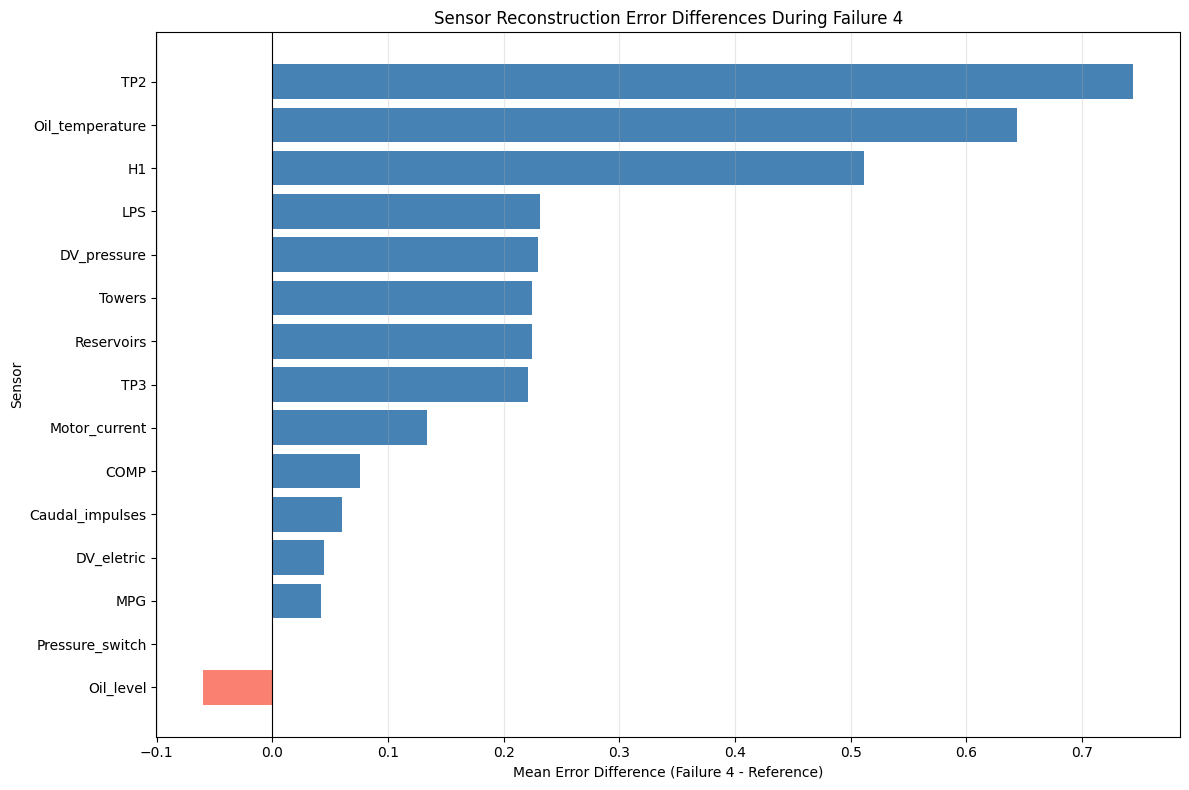

In [12]:
# Visualize sensor reconstruction error differences during Failure 4

import matplotlib.pyplot as plt

# Sort sensors by reconstruction error difference
plot_df = sensor_comparison_df.sort_values(
    'Error Difference',
    ascending=True
)

plt.figure(figsize=(12, 8))

bars = plt.barh(
    plot_df['Sensor'],
    plot_df['Error Difference'],
    color=[
        'steelblue' if value >= 0 else 'salmon'
        for value in plot_df['Error Difference']
    ]
)

# Reference line for no difference
plt.axvline(0, color='black', linewidth=0.8)

plt.title(
    'Sensor Reconstruction Error Differences During Failure 4'
)
plt.xlabel('Mean Error Difference (Failure 4 - Reference)')
plt.ylabel('Sensor')

plt.grid(axis='x', alpha=0.3)
plt.tight_layout()

# Save the figure to Google Drive
plt.savefig(
    autoencoder_dir / 'failure4_sensor_error_differences.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

##### Observation:
##### The bar chart shows the difference in mean sensor reconstruction errors between Failure 4 and the sampled reference windows.
##### TP2, Oil_temperature, and H1 showed the largest increases.
##### Most sensors had higher reconstruction errors during Failure 4, while Oil_level showed a decrease.
##### This supports the earlier finding that several sensors were reconstructed less accurately during Failure 4.

##### Step 15.5: Examine Sensor Reconstruction Errors Across Failure 4 Windows

Selected sensors: ['TP2', 'Oil_temperature', 'H1', 'LPS', 'DV_pressure']


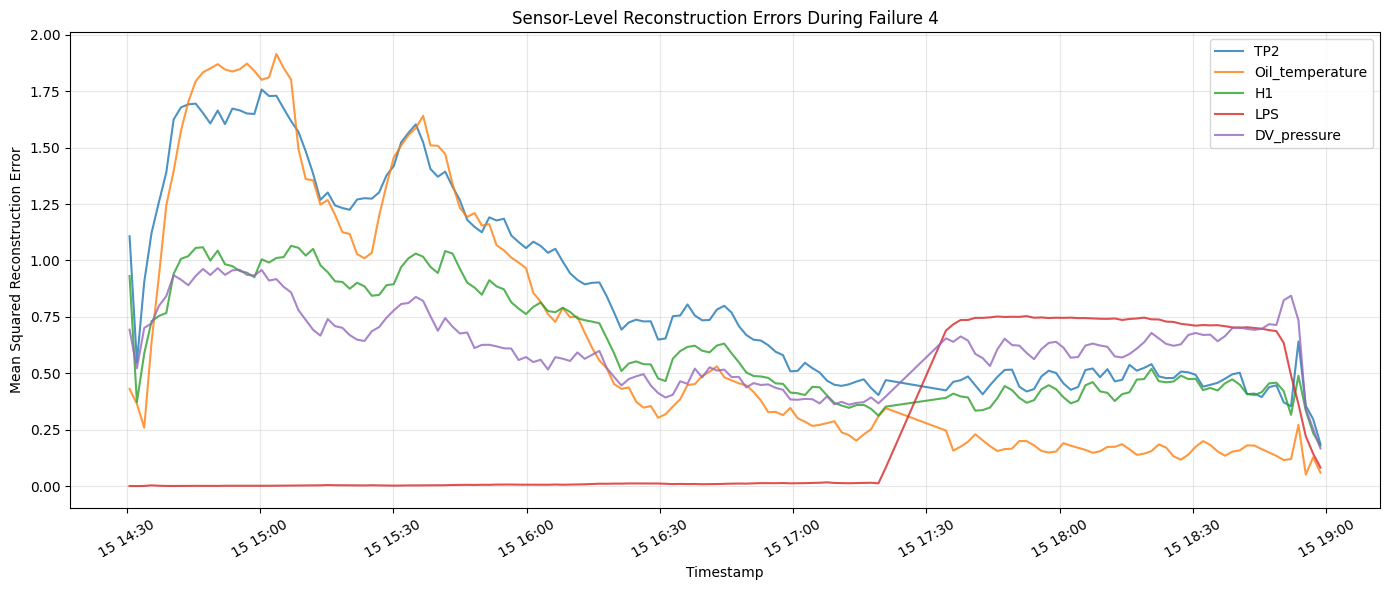

In [13]:
# Step 15.5 - Examine sensor errors across Failure 4 windows

# Build a DataFrame with per-window sensor reconstruction errors
failure4_sensor_df = pd.DataFrame(
    sensor_errors,
    columns=feature_cols
)

# Restore the corresponding window timestamps
failure4_sensor_df['timestamp'] = pd.to_datetime(
    failure4_data.loc[
        eval_window_end_indices[failure4_mask],
        'timestamp'
    ].to_numpy()
)

failure4_sensor_df = failure4_sensor_df.sort_values(
    'timestamp'
).reset_index(drop=True)

# Select sensors with the largest mean error increases
top_sensors = sensor_comparison_df.head(5)['Sensor'].tolist()

print("Selected sensors:", top_sensors)

# Plot reconstruction errors over time
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

for sensor in top_sensors:
    plt.plot(
        failure4_sensor_df['timestamp'],
        failure4_sensor_df[sensor],
        label=sensor,
        alpha=0.8
    )

plt.title('Sensor-Level Reconstruction Errors During Failure 4')
plt.xlabel('Timestamp')
plt.ylabel('Mean Squared Reconstruction Error')
plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=30)
plt.tight_layout()

plt.savefig(
    autoencoder_dir / 'failure4_sensor_reconstruction_errors.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

##### Observation:
##### Sensor-level reconstruction errors changed during Failure 4.
##### TP2 and Oil_temperature showed relatively high errors during the earlier part of the failure period.
##### These errors gradually decreased over time.
##### Later, LPS and DV_pressure showed increased errors, while Oil_temperature remained relatively low.
##### This suggests that different sensors contribute to reconstruction error at different stages of Failure 4.
##### However, the overall AE reconstruction error remained below its anomaly threshold throughout the period.

##### Step 15.6: Compare Sensor Errors Between IF-Detected and Undetected Windows

In [14]:
# Align IF predictions with sensor error windows
failure4_indices = eval_window_end_indices[failure4_mask]

if_predictions = comparison_df.loc[
    failure4_indices, 'if_anomaly'
].to_numpy().astype(bool)

assert len(if_predictions) == len(sensor_errors)
assert if_predictions.sum() == 31

# Calculate mean sensor errors for each group
detected_errors = sensor_errors[if_predictions].mean(axis=0)
undetected_errors = sensor_errors[~if_predictions].mean(axis=0)

if_sensor_comparison = pd.DataFrame({
    'Sensor': feature_cols,
    'IF Detected Mean Error': detected_errors,
    'IF Undetected Mean Error': undetected_errors
})

if_sensor_comparison['Difference'] = (
    if_sensor_comparison['IF Detected Mean Error']
    - if_sensor_comparison['IF Undetected Mean Error']
)

if_sensor_comparison = if_sensor_comparison.sort_values(
    'Difference',
    ascending=False
).reset_index(drop=True)

print("IF detected windows:", if_predictions.sum())
print("IF undetected windows:", (~if_predictions).sum())

display(if_sensor_comparison.round(6))

# Save results
if_sensor_comparison.to_csv(
    autoencoder_dir / 'failure4_if_sensor_error_comparison.csv',
    index=False
)

IF detected windows: 31
IF undetected windows: 125


,Sensor,IF Detected Mean Error,IF Undetected Mean Error,Difference
0,LPS,0.718699,0.112959,0.605740
1,Caudal_impulses,0.158822,0.049480,0.109342
2,Motor_current,0.268750,0.199256,0.069494
3,Oil_level,0.109272,0.049453,0.059819
4,DV_pressure,0.657911,0.615660,0.042250
5,Pressure_switch,0.016574,0.011608,0.004967
6,DV_eletric,0.062882,0.064706,-0.001825
7,Towers,0.259874,0.277540,-0.017666
8,COMP,0.078856,0.100004,-0.021148
9,MPG,0.044368,0.066051,-0.021683


##### Observation:
##### During Failure 4, 31 windows were detected by Isolation Forest and 125 windows were not detected.
##### LPS showed the largest increase in reconstruction error among IF-detected windows.
##### In contrast, TP2 and Oil_temperature had lower errors in IF-detected windows than in undetected windows.
##### This is consistent with the changing sensor-error patterns observed during Failure 4.
##### Since the autoencoder averages reconstruction errors across all 15 features, high errors in individual sensors may not result in a high overall window score.
##### These findings suggest a possible explanation for the difference between the models, but do not establish a causal relationship.

### STEP 16 : Investigate Sensor-Aware Anomaly Scoring

#### STEP 16: Investigate Sensor-Aware Autoencoder Anomaly Scoring

##### Step 16.1: Calculate Sensor-Aware Scores for Validation Windows

In [15]:
import numpy as np

# Load existing validation windows
X_val_windows = np.load(
    data_dir / 'X_val_windows.npy',
    mmap_mode='r'
)

print("Validation windows:", X_val_windows.shape)

# Calculate maximum sensor reconstruction error per window
sensor_aware_val_scores = []

batch_size = 256

for start in range(0, len(X_val_windows), batch_size):

    batch = np.asarray(
        X_val_windows[start:start + batch_size]
    )

    # Reconstruct using the existing trained model
    reconstructed = autoencoder.predict(
        batch,
        verbose=0
    )

    # Mean squared error per sensor across 60 time steps
    sensor_mse = np.mean(
        (batch - reconstructed) ** 2,
        axis=1
    )

    # Maximum error among the 15 sensors
    max_sensor_error = np.max(
        sensor_mse,
        axis=1
    )

    sensor_aware_val_scores.extend(max_sensor_error)

sensor_aware_val_scores = np.array(
    sensor_aware_val_scores
)

# Select threshold using validation data only
sensor_aware_threshold = np.percentile(
    sensor_aware_val_scores,
    99
)

print("\nSensor-aware validation results:")
print("Mean score:", round(sensor_aware_val_scores.mean(), 6))
print("Maximum score:", round(sensor_aware_val_scores.max(), 6))
print("99th percentile threshold:", round(sensor_aware_threshold, 6))

print(
    "Validation anomalies:",
    (sensor_aware_val_scores > sensor_aware_threshold).sum()
)

# Save results separately from the original AE scores
np.save(
    autoencoder_dir / 'sensor_aware_val_scores.npy',
    sensor_aware_val_scores
)

np.save(
    autoencoder_dir / 'sensor_aware_threshold.npy',
    sensor_aware_threshold
)

print("\nSensor-aware validation results saved.")

Validation windows: (13749, 60, 15)

Sensor-aware validation results:
Mean score: 0.562439
Maximum score: 64.66309
99th percentile threshold: 9.108829
Validation anomalies: 138

Sensor-aware validation results saved.


##### Observation:
##### Sensor-aware anomaly scores were calculated using the maximum reconstruction error across 15 sensors.
##### The 99th-percentile validation threshold was 9.108829.
##### A total of 138 validation windows were flagged.
##### The threshold was higher than the original AE threshold because the new method uses maximum sensor error.
##### Further evaluation is needed to determine whether this method improves detection across failure periods.

##### Step 16.2: Calculate Sensor-Aware Scores for Evaluation Windows

In [16]:
# Step 16.2 - Calculate sensor-aware evaluation scores

sensor_aware_eval_scores = []

batch_size = 256

for start in range(0, len(X_eval_windows), batch_size):

    batch = np.asarray(
        X_eval_windows[start:start + batch_size]
    )

    # Reconstruct using the existing autoencoder
    reconstructed = autoencoder.predict(
        batch,
        verbose=0
    )

    # Calculate mean squared error for each sensor
    sensor_mse = np.mean(
        (batch - reconstructed) ** 2,
        axis=1
    )

    # Select the maximum sensor error per window
    max_sensor_error = np.max(
        sensor_mse,
        axis=1
    )

    sensor_aware_eval_scores.append(max_sensor_error)

sensor_aware_eval_scores = np.concatenate(
    sensor_aware_eval_scores
)

# Apply validation-derived threshold
sensor_aware_eval_predictions = (
    sensor_aware_eval_scores > sensor_aware_threshold
)

# Verify dimensions
assert len(sensor_aware_eval_scores) == len(comparison_df)

print("Evaluation windows:", len(sensor_aware_eval_scores))
print("Sensor-aware anomalies:", sensor_aware_eval_predictions.sum())
print(
    "Anomaly rate (%):",
    round(sensor_aware_eval_predictions.mean() * 100, 2)
)

# Save scores and predictions
np.save(
    autoencoder_dir / 'sensor_aware_eval_scores.npy',
    sensor_aware_eval_scores
)

np.save(
    autoencoder_dir / 'sensor_aware_eval_predictions.npy',
    sensor_aware_eval_predictions
)

Evaluation windows: 94307
Sensor-aware anomalies: 4369
Anomaly rate (%): 4.63

Sensor-aware evaluation results saved.


##### Observation:
##### The sensor-aware method flagged 4,369 out of 94,307 evaluation windows (4.63%).
##### This is close to the original autoencoder result of 4,376 windows (4.64%).
##### However, similar anomaly counts do not necessarily indicate that both methods detect the same windows.
##### Further comparison across documented failure periods is needed to evaluate the alternative scoring method.

##### Step 16.3: Compare Anomaly Detection Across Documented Failure Periods

In [17]:
# Align sensor-aware predictions with comparison DataFrame
assert np.array_equal(
    comparison_df.index.to_numpy(),
    eval_window_end_indices
), "Window order does not match"

comparison_three_df = comparison_df.copy()

comparison_three_df['sensor_aware_anomaly'] = (
    sensor_aware_eval_predictions
)

# Compare anomaly rates for each failure period
three_model_results = []

failure_periods = [
    ('Failure 1', '2020-04-18 00:00:00', '2020-04-18 23:59:00'),
    ('Failure 2', '2020-05-29 23:30:00', '2020-05-30 06:00:00'),
    ('Failure 3', '2020-06-05 10:00:00', '2020-06-07 14:30:00'),
    ('Failure 4', '2020-07-15 14:30:00', '2020-07-15 19:00:00')
]

failure_mask = pd.Series(
    False,
    index=comparison_three_df.index
)

for name, start, end in failure_periods:

    period_mask = (
        (comparison_three_df['timestamp'] >= pd.Timestamp(start)) &
        (comparison_three_df['timestamp'] <= pd.Timestamp(end))
    )

    failure_mask |= period_mask

    period_data = comparison_three_df.loc[period_mask]

    result = {'Period': name, 'Windows': len(period_data)}

    for column, label in [
        ('if_anomaly', 'IF'),
        ('ae_anomaly', 'Original AE'),
        ('sensor_aware_anomaly', 'Sensor-Aware AE')
    ]:
        result[f'{label} Anomalies'] = int(period_data[column].sum())
        result[f'{label} Rate (%)'] = round(
            period_data[column].mean() * 100, 2
        )

    three_model_results.append(result)

# Compare windows outside documented failure periods
outside_data = comparison_three_df.loc[~failure_mask]

result = {
    'Period': 'Outside documented failures',
    'Windows': len(outside_data)
}

for column, label in [
    ('if_anomaly', 'IF'),
    ('ae_anomaly', 'Original AE'),
    ('sensor_aware_anomaly', 'Sensor-Aware AE')
]:
    result[f'{label} Anomalies'] = int(outside_data[column].sum())
    result[f'{label} Rate (%)'] = round(
        outside_data[column].mean() * 100, 2
    )

three_model_results.append(result)

three_model_results_df = pd.DataFrame(three_model_results)

display(three_model_results_df)

# Save results
three_model_results_df.to_csv(
    autoencoder_dir / 'three_method_failure_comparison.csv',
    index=False
)

,Period,Windows,IF Anomalies,IF Rate (%),Original AE Anomalies,Original AE Rate (%),Sensor-Aware AE Anomalies,Sensor-Aware AE Rate (%)
0,Failure 1,855,6,0.70,851,99.53,851,99.53
1,Failure 2,236,219,92.80,236,100.00,236,100.00
2,Failure 3,1719,1716,99.83,1719,100.00,1718,99.94
3,Failure 4,156,31,19.87,0,0.00,0,0.00
4,Outside documented failures,91341,1233,1.35,1570,1.72,1564,1.71



Three-method comparison saved.


##### Observation:
##### The original autoencoder and sensor-aware autoencoder produced very similar anomaly detection results.
##### Both methods detected almost all windows during Failures 1, 2, and 3.
##### Neither method detected any windows during Failure 4.
##### The sensor-aware method flagged one fewer window during Failure 3 and six fewer windows outside documented failure periods.
##### Therefore, maximum sensor reconstruction error did not provide a meaningful improvement over the original mean reconstruction error in this experiment.

In [18]:
# Step 16.4 - Verify sensor-aware scores during Failure 4

failure4_positions = np.flatnonzero(
    (comparison_three_df['timestamp'] >= '2020-07-15 14:30:00') &
    (comparison_three_df['timestamp'] <= '2020-07-15 19:00:00')
)

failure4_sensor_aware_scores = sensor_aware_eval_scores[
    failure4_positions
]

print("Failure 4 windows:", len(failure4_sensor_aware_scores))
print("Minimum score:", round(failure4_sensor_aware_scores.min(), 6))
print("Mean score:", round(failure4_sensor_aware_scores.mean(), 6))
print("Maximum score:", round(failure4_sensor_aware_scores.max(), 6))
print("Validation threshold:", round(sensor_aware_threshold, 6))

print(
    "Windows above threshold:",
    (failure4_sensor_aware_scores > sensor_aware_threshold).sum()
)

assert len(failure4_sensor_aware_scores) == 156
assert (failure4_sensor_aware_scores > sensor_aware_threshold).sum() == 0

print("\nFailure 4 sensor-aware score verification passed.")

Failure 4 windows: 156
Minimum score: 0.18751
Mean score: 0.966603
Maximum score: 1.914598
Validation threshold: 9.108829
Windows above threshold: 0

Failure 4 sensor-aware score verification passed.


##### Observation:
##### The maximum sensor-aware score during Failure 4 was 1.914598, below the validation threshold of 9.108829.
##### Therefore, none of the 156 Failure 4 windows were flagged.
##### The sensor-aware method did not overcome the original autoencoder's limitation in detecting Failure 4.
##### This suggests that changing the reconstruction-error aggregation method alone is insufficient under the current validation-based threshold.

### STEP 17: Final Model Comparison and Evaluation Summary

In [19]:
# Step 17.1 - Overall comparison across documented failure periods

# Identify windows inside and outside documented failure periods
inside_mask = comparison_three_df['failure_period'] == 1
outside_mask = comparison_three_df['failure_period'] == 0

# Verify the expected evaluation window counts
assert inside_mask.sum() == 2966
assert outside_mask.sum() == 91341

overall_results = []

for model_name, column in [
    ('Isolation Forest', 'if_anomaly'),
    ('Original Autoencoder', 'ae_anomaly'),
    ('Sensor-Aware Autoencoder', 'sensor_aware_anomaly')
]:

    inside_count = int(
        comparison_three_df.loc[inside_mask, column].sum()
    )

    outside_count = int(
        comparison_three_df.loc[outside_mask, column].sum()
    )

    overall_results.append({
        'Model': model_name,
        'Inside Failure Windows': inside_count,
        'Inside Anomaly Rate (%)': round(
            inside_count / inside_mask.sum() * 100, 2
        ),
        'Outside Failure Windows': outside_count,
        'Outside Anomaly Rate (%)': round(
            outside_count / outside_mask.sum() * 100, 2
        ),
        'Total Anomalies': inside_count + outside_count
    })

overall_comparison_df = pd.DataFrame(overall_results)

display(overall_comparison_df)

# Save the overall comparison
overall_comparison_df.to_csv(
    autoencoder_dir / 'overall_model_comparison.csv',
    index=False
)

,Model,Inside Failure Windows,Inside Anomaly Rate (%),Outside Failure Windows,Outside Anomaly Rate (%),Total Anomalies
0,Isolation Forest,1972,66.49,1233,1.35,3205
1,Original Autoencoder,2806,94.61,1570,1.72,4376
2,Sensor-Aware Autoencoder,2805,94.57,1564,1.71,4369



Overall model comparison saved.


##### Observation:
##### The original autoencoder achieved the highest anomaly detection rate within documented failure periods (94.61%), compared with Isolation Forest (66.49%) and the sensor-aware autoencoder (94.57%).
##### Isolation Forest had the lowest anomaly rate outside documented failure periods (1.35%).
##### The sensor-aware scoring method did not provide a meaningful improvement over the original autoencoder.
##### However, Isolation Forest detected some Failure 4 windows that both autoencoder methods missed.
##### These results indicate that the methods have different detection strengths and limitations.

In [21]:
# Step 17.2 - Compare anomaly prediction agreement

if_flags = comparison_three_df['if_anomaly'].astype(bool)
ae_flags = comparison_three_df['ae_anomaly'].astype(bool)

# Four possible prediction combinations
both_detected = (if_flags & ae_flags).sum()
if_only = (if_flags & ~ae_flags).sum()
ae_only = (~if_flags & ae_flags).sum()
neither_detected = (~if_flags & ~ae_flags).sum()

agreement_df = pd.DataFrame({
    'Detection Category': [
        'Both models flagged',
        'Isolation Forest only',
        'Autoencoder only',
        'Neither model flagged'
    ],
    'Windows': [
        both_detected,
        if_only,
        ae_only,
        neither_detected
    ]
})

agreement_df['Percentage (%)'] = (
    agreement_df['Windows'] / len(comparison_three_df) * 100
).round(2)

display(agreement_df)

# Verify that every window is included exactly once
assert agreement_df['Windows'].sum() == len(comparison_three_df)

# Calculate overlap among flagged windows
union_count = (if_flags | ae_flags).sum()

jaccard_similarity = (
    both_detected / union_count
    if union_count > 0 else 1.0
)

print(
    "\nJaccard similarity:",
    round(jaccard_similarity, 4)
)

# Save results
agreement_df.to_csv(
    autoencoder_dir / 'if_ae_detection_agreement.csv',
    index=False
)

,Detection Category,Windows,Percentage (%)
0,Both models flagged,3142,3.33
1,Isolation Forest only,63,0.07
2,Autoencoder only,1234,1.31
3,Neither model flagged,89868,95.29



Jaccard similarity: 0.7078


##### Observation:
##### Isolation Forest and the Autoencoder flagged 3,142 common evaluation windows, with a Jaccard similarity of 0.7078.
##### The Autoencoder uniquely flagged 1,234 windows, while Isolation Forest uniquely flagged 63 windows.
##### This indicates substantial overlap between the models, although each also identified different windows.
##### These differences suggest potential complementary detection behaviour, which could be investigated through a combined approach in future work.

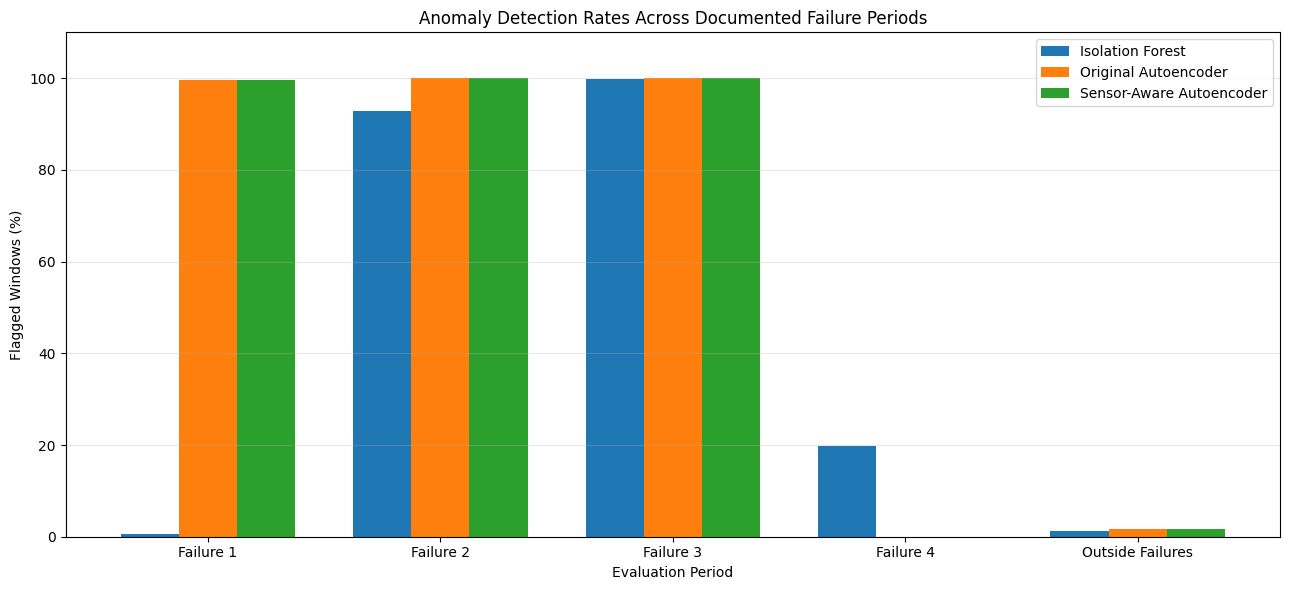

In [22]:
# Step 17.3 - Visualize anomaly detection rates

import matplotlib.pyplot as plt
import numpy as np

plot_df = three_model_results_df.copy()

periods = plot_df['Period'].tolist()

if_rates = plot_df['IF Rate (%)'].to_numpy()
ae_rates = plot_df['Original AE Rate (%)'].to_numpy()
sensor_rates = plot_df['Sensor-Aware AE Rate (%)'].to_numpy()

x = np.arange(len(periods))
width = 0.25

fig, ax = plt.subplots(figsize=(13, 6))

ax.bar(
    x - width,
    if_rates,
    width,
    label='Isolation Forest'
)

ax.bar(
    x,
    ae_rates,
    width,
    label='Original Autoencoder'
)

ax.bar(
    x + width,
    sensor_rates,
    width,
    label='Sensor-Aware Autoencoder'
)

ax.set_xlabel('Evaluation Period')
ax.set_ylabel('Flagged Windows (%)')
ax.set_title(
    'Anomaly Detection Rates Across Documented Failure Periods'
)

ax.set_xticks(x)
ax.set_xticklabels(
    ['Failure 1', 'Failure 2', 'Failure 3',
     'Failure 4', 'Outside Failures']
)

ax.set_ylim(0, 110)
ax.legend()
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()

plt.savefig(
    autoencoder_dir / 'final_model_detection_comparison.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [24]:
comparison_three_df.to_csv(
    autoencoder_dir / 'three_method_window_predictions.csv',
    index=True
)

In [25]:
# Verify saved outputs from Steps 16 and 17

required_files = [
    'sensor_aware_val_scores.npy',
    'sensor_aware_threshold.npy',
    'sensor_aware_eval_scores.npy',
    'sensor_aware_eval_predictions.npy',
    'three_method_failure_comparison.csv',
    'overall_model_comparison.csv',
    'if_ae_detection_agreement.csv',
    'final_model_detection_comparison.png'
]

missing_files = []

for filename in required_files:
    file_path = autoencoder_dir / filename

    if file_path.exists() and file_path.stat().st_size > 0:
        print(f"Saved: {filename}")
    else:
        print(f"MISSING: {filename}")
        missing_files.append(filename)

print("\nVerification complete.")

if not missing_files:
    print("All Step 16 and 17 outputs are saved successfully.")
else:
    print("Missing files:", missing_files)

Saved: sensor_aware_val_scores.npy
Saved: sensor_aware_threshold.npy
Saved: sensor_aware_eval_scores.npy
Saved: sensor_aware_eval_predictions.npy
Saved: three_method_failure_comparison.csv
Saved: overall_model_comparison.csv
Saved: if_ae_detection_agreement.csv
Saved: final_model_detection_comparison.png

Verification complete.
All Step 16 and 17 outputs are saved successfully.
